# 1. 데이터 전처리
## 1-1. 라이브러리 불러오기

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

from imblearn.pipeline import Pipeline      # SMOTE를 넣으려면 imblearn의 Pipeline 사용
from imblearn.over_sampling import SMOTE

RANDOM_STATE = 42

## 1-2. 데이터 통계치 확인

In [2]:
import pandas as pd

df = pd.read_csv('./bank-full.csv', sep=';')
print('\n데이터 행 열 개수')
print(df.shape)
print('\n데이터 숫자 통계치')
print(df.describe(include='all'))
print('\n칼럼명 확인')
print(df.columns.tolist())
print('\n칼럼별 결측치 확인')
print(df.isnull().sum())
print('\n중복 데이터 확인')
print(df.duplicated().sum())


데이터 행 열 개수
(45211, 17)

데이터 숫자 통계치
                 age          job  marital  education default        balance  \
count   45211.000000        45211    45211      45211   45211   45211.000000   
unique           NaN           12        3          4       2            NaN   
top              NaN  blue-collar  married  secondary      no            NaN   
freq             NaN         9732    27214      23202   44396            NaN   
mean       40.936210          NaN      NaN        NaN     NaN    1362.272058   
std        10.618762          NaN      NaN        NaN     NaN    3044.765829   
min        18.000000          NaN      NaN        NaN     NaN   -8019.000000   
25%        33.000000          NaN      NaN        NaN     NaN      72.000000   
50%        39.000000          NaN      NaN        NaN     NaN     448.000000   
75%        48.000000          NaN      NaN        NaN     NaN    1428.000000   
max        95.000000          NaN      NaN        NaN     NaN  102127.000000   

   

## 1-3. unknown 현황 확인(건수, 비율)

In [3]:
# unknown 현황 다시 확인
unknown_cols = ['job', 'education', 'contact', 'poutcome']
for col in unknown_cols:
    print(f"{col}: {(df[col] == 'unknown').sum()}건 ({(df[col] == 'unknown').mean()*100:.2f}%)")

# job: 행 삭제 / education: 직업별 최빈값 대체 (1-5에서 처리)
# contact, poutcome: 별도 대체 없이 'unknown'을 하나의 범주로 유지
# → 이후 원-핫 인코딩 시 contact_unknown, poutcome_unknown으로 자동 생성됨

job: 288건 (0.64%)
education: 1857건 (4.11%)
contact: 13020건 (28.80%)
poutcome: 36959건 (81.75%)


## 1-4. 데이터 중복치 탐지 및 X, y 분리

- duration 칼럼이 데이터 누수를 발생시키기 때문에 모델링 과정에서 제외함.
- duration 칼럼 제외 후 중복 건수가 16건(전체의 약 0.035%) 발생함.
- 비율은 매우 작지만, 동일한 행이 Train과 Test에 나뉘어 들어가는 누수를 막기 위해 분할 전에 제거함.
- 이 셀에서 X, y를 만들기 때문에 반드시 1-5(분할)보다 먼저 실행해야 함.
- 참고: 완전히 같은 행은 아니지만 같은 고객이 여러 캠페인에 걸쳐 반복 등장하는 경우도 확인됨. 현재 단계에서는 duration 제거로 생긴 중복만 처리하고, 반복 고객 문제는 추후 모델 평가에서 문제가 될 경우 고객 단위 분할 등으로 고려함.

In [4]:
df = pd.read_csv('bank-full.csv', sep=';')

df = df.drop(columns=['duration'])
print('중복 건수:', df.duplicated().sum())   # 16

df = df.drop_duplicates().reset_index(drop=True)
print('제거 후 shape:', df.shape)            # (45195, 16)

X = df.drop(columns=['y'])
y = (df['y'] == 'yes').astype(int)

중복 건수: 16
제거 후 shape: (45195, 16)


## 1-5. 데이터 분할 및 결측치 전처리
#### job은 행 삭제
#### education은 직업별 최빈값 대체 (Train 기준 계산 → Val·Test에 동일 적용)

In [5]:
# 1) Train / Val / Test = 60 : 20 : 20 분할
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

# 2) 각 데이터셋에서 job unknown 행 삭제 (X와 y를 같은 행으로 삭제)
def drop_job_unknown(X_part, y_part):
    keep = X_part['job'] != 'unknown'
    return X_part[keep].copy(), y_part[keep].copy()

X_train, y_train = drop_job_unknown(X_train, y_train)
X_val,   y_val   = drop_job_unknown(X_val,   y_val)
X_test,  y_test  = drop_job_unknown(X_test,  y_test)

# 3) Train에서만 직업별 education 최빈값 계산 (job unknown 삭제 후)
edu_map = (X_train[X_train['education'] != 'unknown']
           .groupby('job')['education']
           .agg(lambda s: s.mode()[0]))

# 4) Train / Val / Test에 같은 최빈값으로 대체
for data in [X_train, X_val, X_test]:
    mask = data['education'] == 'unknown'
    data.loc[mask, 'education'] = data.loc[mask, 'job'].map(edu_map)

# 5) 확인
for name, data, target in [('Train', X_train, y_train), ('Val', X_val, y_val), ('Test', X_test, y_test)]:
    print(f"{name}: {data.shape}, 가입 비율 {target.mean()*100:.2f}%, "
          f"NaN {data.isna().sum().sum()}건, "
          f"job unknown {(data['job'] == 'unknown').sum()}건, "
          f"education unknown {(data['education'] == 'unknown').sum()}건")

Train: (26931, 15), 가입 비율 11.70%, NaN 0건, job unknown 0건, education unknown 0건
Val: (8986, 15), 가입 비율 11.70%, NaN 0건, job unknown 0건, education unknown 0건
Test: (8990, 15), 가입 비율 11.71%, NaN 0건, job unknown 0건, education unknown 0건


In [6]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

check = pd.DataFrame({
    name: (data[cat_cols] == 'unknown').sum()
    for name, data in [('Train', X_train), ('Val', X_val), ('Test', X_test)]
})
print(check)

           Train   Val  Test
job            0     0     0
marital        0     0     0
education      0     0     0
default        0     0     0
housing        0     0     0
loan           0     0     0
contact     7797  2491  2619
month          0     0     0
poutcome   21996  7357  7335


In [7]:
for name, data in [('Train', X_train), ('Val', X_val), ('Test', X_test)]:
    print(f"{name} - NaN: {data.isna().sum().sum()}건, "
          f"job unknown: {(data['job'] == 'unknown').sum()}건, "
          f"education unknown: {(data['education'] == 'unknown').sum()}건")

Train - NaN: 0건, job unknown: 0건, education unknown: 0건
Val - NaN: 0건, job unknown: 0건, education unknown: 0건
Test - NaN: 0건, job unknown: 0건, education unknown: 0건


#### education 대체 근거: 직업과 학력의 연관성
- 직업과 학력은 둘 다 범주형 변수이므로, 피어슨 상관계수 대신 교차표 · 카이제곱 검정 · Cramér's V로 관계를 확인함.
  - 카이제곱 검정: '두 변수가 서로 관련이 없다'는 가정을 검정 (p < 0.05이면 관련 있음)
  - Cramér's V: 관련의 강도를 0~1로 표현 (0.1 이상 약함, 0.3 이상 중간, 0.5 이상 강함)
- 누수 방지를 위해 Train 데이터 중 job과 education이 모두 알려진 행만 사용함.
  - X_train의 education은 이미 대체된 상태이므로, 대체 전 원본인 `X.loc[X_train.index]`에서 가져옴.

In [8]:
base = X.loc[X_train.index]      # 대체 전 Train 원본 (job unknown은 이미 제외된 행)
known = base[(base['job'] != 'unknown') & (base['education'] != 'unknown')].copy()
print('분석 대상:', len(known), '건')

edu_by_job = (pd.crosstab(known['job'], known['education'], normalize='index') * 100).round(1)
edu_by_job

분석 대상: 25893 건


education,primary,secondary,tertiary
job,,,
admin.,4.1,84.3,11.6
blue-collar,40.7,57.7,1.6
entrepreneur,12.3,36.9,50.8
housemaid,52.4,33.7,13.9
management,3.2,11.7,85.1
retired,36.7,45.9,17.5
self-employed,7.7,37.7,54.6
services,8.5,86.3,5.1
student,5.8,63.8,30.5


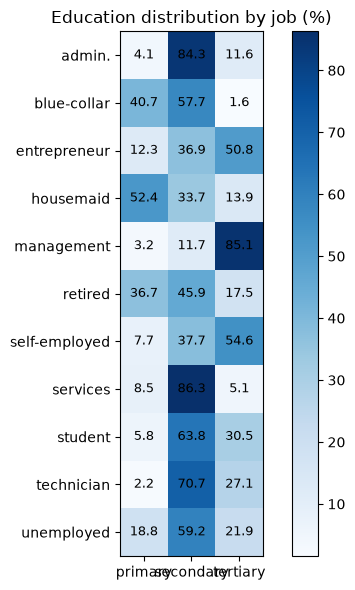

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(edu_by_job.values, cmap='Blues')
ax.set_xticks(range(edu_by_job.shape[1])); ax.set_xticklabels(edu_by_job.columns)
ax.set_yticks(range(edu_by_job.shape[0])); ax.set_yticklabels(edu_by_job.index)
for i in range(edu_by_job.shape[0]):
    for j in range(edu_by_job.shape[1]):
        ax.text(j, i, edu_by_job.values[i, j], ha='center', va='center', fontsize=9)
ax.set_title('Education distribution by job (%)')
plt.colorbar(im)
plt.tight_layout()
plt.show()

In [10]:
from scipy.stats import chi2_contingency

def cramers_v(data, col, target='education'):
    table = pd.crosstab(data[col], data[target])
    chi2, p, dof, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    return chi2, p, v

chi2, p, v = cramers_v(known, 'job')
print(f"직업 vs 학력 → 카이제곱 = {chi2:,.1f}, p-value = {p:.3g}, Cramér's V = {v:.3f}")

직업 vs 학력 → 카이제곱 = 16,040.2, p-value = 0, Cramér's V = 0.557


In [11]:
# 다른 변수와 비교: 학력을 추정하기에 직업이 가장 적합한가?
known['age_group'] = pd.cut(known['age'], bins=[0, 29, 39, 49, 59, 100])

compare = pd.DataFrame({
    col: {"Cramér's V": round(cramers_v(known, col)[2], 3)}
    for col in ['job', 'age_group', 'marital', 'housing', 'contact', 'loan', 'default']
}).T.sort_values("Cramér's V", ascending=False)
compare

,Cramér's V
job,0.557
age_group,0.153
marital,0.127
contact,0.124
housing,0.110
loan,0.061
default,0.011


#### 직업-학력 연관성 판단
- 직업별 학력 분포가 뚜렷하게 구분됨: management는 85.1%가 tertiary, services(86.3%)와 admin.(84.3%)은 대부분 secondary, housemaid는 52.4%가 primary.
- 카이제곱 검정 결과 p < 0.001로 직업과 학력 사이에 통계적으로 유의한 관계가 있으며, Cramér's V = 0.557로 강한 연관성을 보임.
- 다른 변수와 비교하면 연령대(0.153), 결혼 상태(0.127), 연락 방식(0.124) 등보다 3배 이상 높아, 학력을 추정하기에 직업이 가장 적합한 변수임.
- 연령대를 함께 사용해도 대체 정확도가 거의 오르지 않았던 이유도, 연령대와 학력의 연관성이 직업에 비해 약하기 때문으로 설명됨.
- 결론: education의 unknown은 Train 기준 직업별 최빈값으로 대체함.

## 1-6. 데이터 이상치 탐지

In [12]:
import matplotlib.pyplot as plt
num_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

#### IQR로 이상치 후보 탐지
- pdays와 previous는 IQR이 0. (값이 대부분 -1과 0이어서, 이전 연락 기록이 있는 고객 전체가 이상치로 잡힌 것으로 판단됨.) -> 이 두 변수는 IQR로 판단하면 안 된다.

In [13]:
rows = []
for col in num_cols:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = (X_train[col] < lower) | (X_train[col] > upper)

    rows.append({
        '컬럼': col, '하한': lower, '상한': upper,
        '이상치 건수': out.sum(),
        '비율(%)': round(out.mean() * 100, 2),
        '이상치 가입률(%)': round(y_train[out].mean() * 100, 1) if out.any() else None,
        '정상 가입률(%)': round(y_train[~out].mean() * 100, 1)
    })

iqr_table = pd.DataFrame(rows).set_index('컬럼')
display(iqr_table)

,하한,상한,이상치 건수,비율(%),이상치 가입률(%),정상 가입률(%)
컬럼,,,,,,
age,10.5,70.5,287,1.07,44.3,11.3
balance,-1944.5,3443.5,2829,10.50,16.0,11.2
day,-11.5,40.5,0,0.00,NaN,11.7
campaign,-2.0,6.0,1821,6.76,5.1,12.2
pdays,-1.0,-1.0,4939,18.34,22.6,9.3
previous,0.0,0.0,4939,18.34,22.6,9.3


#### 시각화로 분포 확인
시각화 목적:
- 극단값이 몇 개만 동떨어져 있는지, 아니면 꼬리가 길게 이어지는지
- 분포가 한쪽으로 얼마나 치우쳐 있는지
- 이상치가 가입 여부(y)와 관련이 있는지

#### 박스플롯 + 히스토그램

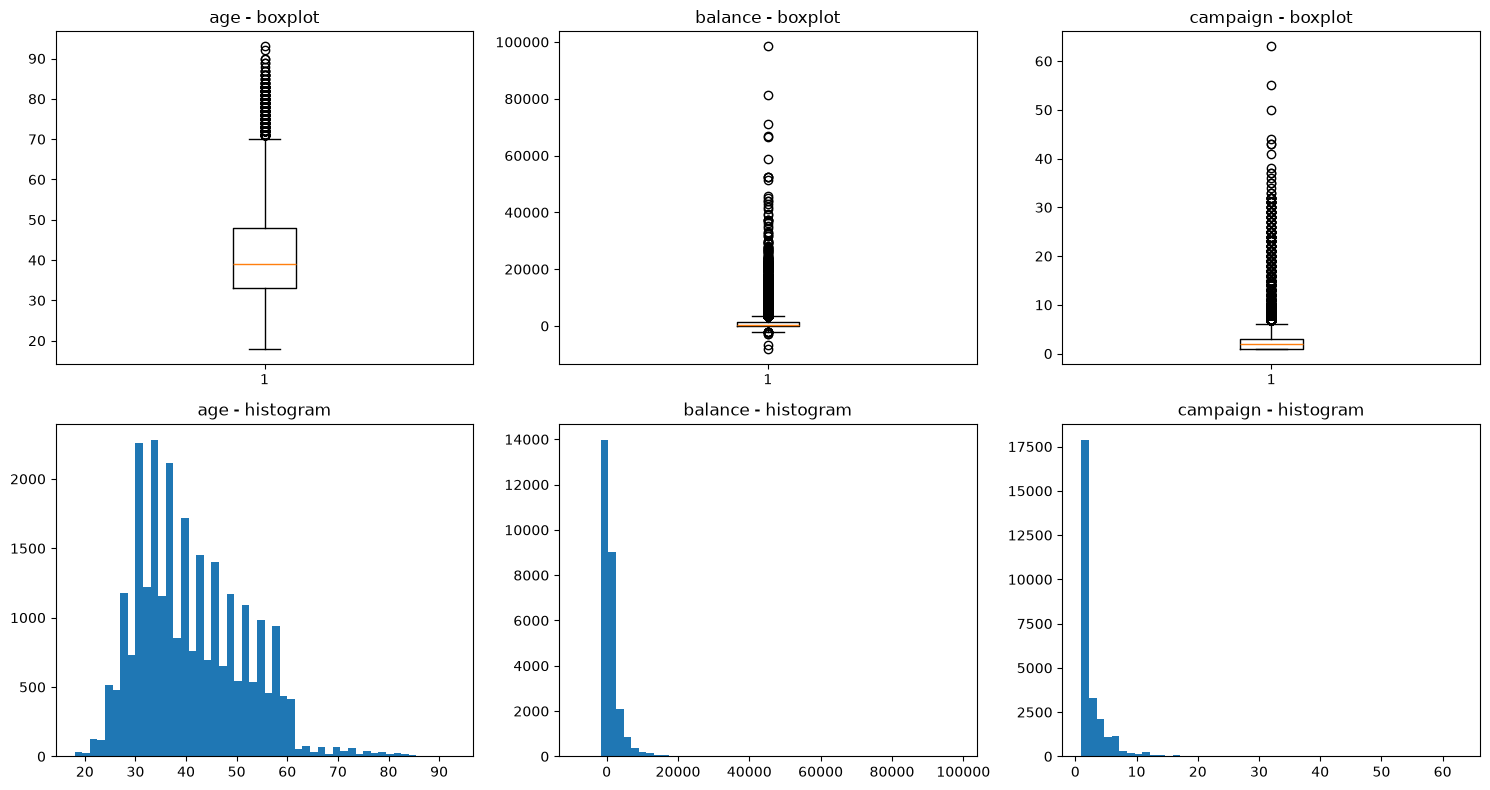

In [14]:
check_cols = ['age', 'balance', 'campaign']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(check_cols):
    axes[0, i].boxplot(X_train[col])
    axes[0, i].set_title(f'{col} - boxplot')

    axes[1, i].hist(X_train[col], bins=50)
    axes[1, i].set_title(f'{col} - histogram')
plt.tight_layout()
plt.show()

#### 박스플롯 + 히스토그램 해석
- age (나이): 
age는 상자가 약 33~48세, 중앙값이 약 39세로 고객 대부분이 25~60세에 분포하며, 60세를 넘으면 고객 수가 급격히 줄어든다. 박스플롯에서 70세를 넘는 값이 이상치로 표시되었으나, 71세부터 93세까지 띄엄띄엄 떨어지지 않고 연속적으로 이어져 있어 입력 오류가 아닌 실제 고령 고객층으로 판단하였다. 따라서 age의 이상치는 별도로 처리하지 않고 유지한다.

- balance (잔고): 
balance는 대부분 고객의 잔고가 0~5,000 근처에 몰려 있고, 소수의 고액 잔고 고객으로 인해 오른쪽으로 꼬리가 매우 긴 분포를 보인다. 이상치는 약 45,000까지 촘촘히 이어지다가 6만~10만 사이에 드문드문 존재하며, 0 아래로도 약 -8,000까지 음수 잔고가 나타난다. 고액 잔고와 음수 잔고(마이너스 통장 등)는 모두 현실적으로 가능한 값이므로 유지하되, 분포의 치우침이 심해 Logistic Regression 적용 시 로그 변환을 검토한다.

- campaign (이번 캠페인 연락 횟수): 
campaign은 고객 대부분이 1~3회 연락을 받았으며, 연락 횟수가 늘수록 고객 수가 빠르게 줄어드는 오른쪽으로 꼬리가 긴 분포를 보인다. 7회부터 약 40회까지 이상치가 연속적으로 이어지고, 50, 55, 63회와 같이 일부 값만 동떨어져 있다. 이는 같은 고객에게 여러 번 연락한 실제 기록으로 볼 수 있고 0회 이하와 같은 규칙 위반도 없으므로 유지하되, Logistic Regression 적용 시 상위 값을 잘라내는 클리핑을 검토한다.

#### 가입 여부별 박스 플롯

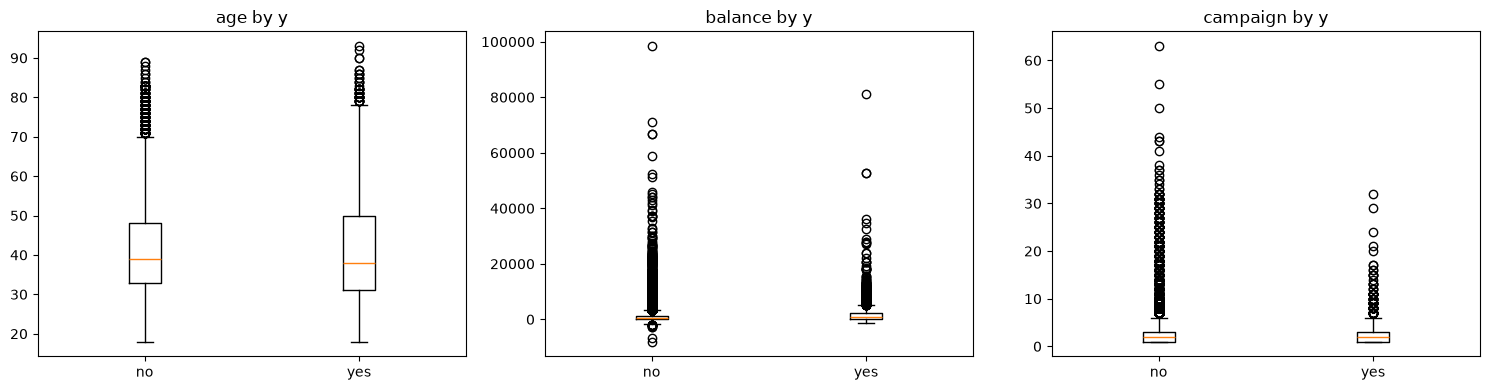

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, check_cols):
    ax.boxplot([X_train.loc[y_train == 0, col], X_train.loc[y_train == 1, col]],
               tick_labels=['no', 'yes'])
    ax.set_title(f'{col} by y')
plt.tight_layout()
plt.show()

#### 가입 여부별 박스플롯 해석
- age (나이): 
가입 고객과 미가입 고객의 중앙값은 각각 약 38세, 39세로 비슷하지만, 가입 고객의 상자(약 31~50세)가 미가입 고객(약 33~48세)보다 위아래로 더 넓게 퍼져 있다. 특히 위쪽 수염이 미가입 고객은 70세에서 끝나는 반면 가입 고객은 약 78세까지 이어져, 가입 고객 중 고령층의 비중이 상대적으로 크다는 것을 알 수 있다. 즉 나이의 평균적인 수준보다는 젊은 층과 고령층처럼 양 끝 연령대에서 가입 경향이 나타나며, 고령 고객의 이상치는 가입 여부를 구분하는 데 유용한 정보로 판단된다.

- balance (잔고): 
두 그룹 모두 상자가 0 근처에 납작하게 눌려 있으나, 가입 고객의 상자가 미가입 고객보다 약간 위쪽으로 넓게 형성되어 있어 가입 고객의 잔고가 전반적으로 조금 더 높은 경향을 보인다. 음수 잔고는 미가입 고객에서 약 -8,000까지 나타나는 반면 가입 고객에서는 0에 가까운 범위에 그친다. 다만 고액 잔고 이상치는 두 그룹 모두에 존재해 특정 그룹에만 나타나는 값이 아니며, 극단값으로 인해 축 범위가 넓어져 차이를 자세히 보기 어려우므로 로그 변환 후 다시 확인할 필요가 있다.

- campaign (이번 캠페인 연락 횟수): 
두 그룹 모두 상자가 1~3회, 중앙값이 약 2회로 일반적인 연락 횟수는 비슷하다. 그러나 미가입 고객은 이상치가 63회까지 이어지는 반면, 가입 고객은 최대 약 32회에 그치고 20회 이상은 드물게 나타난다. 이는 많이 연락한다고 해서 가입으로 이어지지 않으며, 연락 횟수가 매우 많은 고객은 대부분 가입하지 않았음을 보여준다.

#### 꼬리부분 확인(백분위수)


In [16]:
print(X_train[check_cols].describe(percentiles=[0.01, 0.99]).round(1))

           age  balance  campaign
count  26931.0  26931.0   26931.0
mean      40.8   1352.9       2.8
std       10.6   2996.9       3.1
min       18.0  -8019.0       1.0
1%        23.0   -624.7       1.0
99%       71.0  12956.0      16.0
max       93.0  98417.0      63.0


#### 확인 및 판단 내용
- age: 99% 지점이 71세이고 최대는 93세입니다. 70세 이상 고객이 꾸준히 이어져 있어, 동떨어진 오류값이 아니라 고령층 고객군으로 보입니다.
- balance: 오른쪽 꼬리가 매우 깁니다. 99% 지점이 약 13,000인데 최대값은 약 98,000입니다. 
- campaign: 99% 지점이 16회인데 최대 63회까지 있습니다. 40회 이상은 몇 건씩만 드문드문 있습니다.

#### 도메인으로 규칙 판단
- 오류값: 현실에서 불가능한 값(-5세, 32일등) -> 삭제 및 수정
- 극단값: 드물지만 실제로 있을 수 있는 값(93세 등) -> 유지

#### 오류값 규칙 점검

In [17]:
rules = {
    'age':      (X_train['age'] < 18) | (X_train['age'] > 100),   # 성인 고객, 100세 이하
    'day':      (X_train['day'] < 1) | (X_train['day'] > 31),     # 날짜 범위
    'campaign': X_train['campaign'] < 1,                          # 현재 캠페인에서 최소 1회는 연락
    'previous': X_train['previous'] < 0,                          # 횟수는 음수 불가
    'pdays':    (X_train['pdays'] < -1) | (X_train['pdays'] == 0) # -1(연락 없음) 또는 양수만 가능
}

for col, violated in rules.items():
    print(f"{col}: 규칙 위반 {violated.sum()}건")

age: 규칙 위반 0건
day: 규칙 위반 0건
campaign: 규칙 위반 0건
previous: 규칙 위반 0건
pdays: 규칙 위반 0건


#### 극단값 세부 확인

In [18]:
print('음수 잔액 비율:', round((X_train['balance'] < 0).mean() * 100, 2), '%')
print('71세 이상(IQR 상한 70.5세 초과):', (X_train['age'] > 70.5).sum(), '건')
print('잔고 50,000 초과:', (X_train['balance'] > 50000).sum(), '건')
print('campaign 상위 값:', X_train['campaign'].value_counts().sort_index().tail(8).to_dict())

음수 잔액 비율: 8.31 %
71세 이상(IQR 상한 70.5세 초과): 287 건
잔고 50,000 초과: 10 건
campaign 상위 값: {37: 2, 38: 1, 41: 1, 43: 2, 44: 1, 50: 1, 55: 1, 63: 1}


#### previous 오류값 처리
- previous의 최대값 275는 다음으로 큰 값(58)과 약 5배 차이가 나며 혼자 동떨어져 있음.
- 다른 극단값처럼 연속적으로 이어지지 않으므로 입력 오류로 판단함.
- 특정 값(275)을 지우는 대신 'previous가 100을 초과하면 오류값'이라는 규칙을 정해 Train / Val / Test에 동일하게 적용함.
- 계산이 필요 없는 규칙 기반 처리이므로 데이터 누수가 발생하지 않음.

In [19]:
# previous 상위 값 확인 (Train / Val / Test)
for name, data in [('Train', X_train), ('Val', X_val), ('Test', X_test)]:
    print(f"{name} previous 상위 값:", sorted(data['previous'])[-6:])

Train previous 상위 값: [37, 38, 40, 41, 51, 275]
Val previous 상위 값: [25, 26, 29, 30, 55, 58]
Test previous 상위 값: [27, 28, 28, 29, 35, 38]


In [20]:
def drop_previous_error(X_part, y_part, limit=100):
    keep = X_part['previous'] <= limit
    print(f"previous > {limit} 삭제: {(~keep).sum()}건")
    return X_part[keep].copy(), y_part[keep].copy()

X_train, y_train = drop_previous_error(X_train, y_train)
X_val,   y_val   = drop_previous_error(X_val,   y_val)
X_test,  y_test  = drop_previous_error(X_test,  y_test)

for name, data, target in [('Train', X_train, y_train), ('Val', X_val, y_val), ('Test', X_test, y_test)]:
    print(f"{name}: {data.shape}, 가입 비율 {target.mean()*100:.2f}%, previous 최대값 {data['previous'].max()}")

previous > 100 삭제: 1건
previous > 100 삭제: 0건
previous > 100 삭제: 0건
Train: (26930, 15), 가입 비율 11.70%, previous 최대값 51
Val: (8986, 15), 가입 비율 11.70%, previous 최대값 58
Test: (8990, 15), 가입 비율 11.71%, previous 최대값 38


#### pdays 이상치 탐지 (IQR · Z-score · 백분위수)
- pdays는 약 82%가 -1(이전 연락 없음)이라 전체 데이터에 그대로 적용하면 평균·표준편차·사분위수가 왜곡됨.
- 따라서 pdays != -1인 이전 연락 고객만 대상으로 세 가지 방법을 비교함.
  - IQR: Q1 − 1.5×IQR 미만, Q3 + 1.5×IQR 초과
  - Z-score: |z| > 3 (정규분포 가정)
  - 백분위수: 하위 1% 미만, 상위 99% 초과

In [21]:
mask = X_train['pdays'] != -1            # 이전 연락 고객만
p, yp = X_train.loc[mask, 'pdays'], y_train[mask]
print('이전 연락 고객 수:', len(p), '| 왜도(skew):', round(p.skew(), 2))
print(p.describe().round(1))

이전 연락 고객 수: 4938 | 왜도(skew): 0.64
count    4938.0
mean      225.0
std       113.4
min         1.0
25%       138.0
50%       195.0
75%       326.8
max       871.0
Name: pdays, dtype: float64


In [22]:
# 1) IQR
q1, q3 = p.quantile([0.25, 0.75]); iqr = q3 - q1
iqr_lo, iqr_hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_iqr = (p < iqr_lo) | (p > iqr_hi)

# 2) Z-score
z = (p - p.mean()) / p.std()
out_z = z.abs() > 3
z_hi = p.mean() + 3 * p.std()

# 3) 백분위수 (1% ~ 99%)
pct_lo, pct_hi = p.quantile([0.01, 0.99])
out_pct = (p < pct_lo) | (p > pct_hi)

pdays_table = pd.DataFrame([
    ['IQR',      f'{iqr_lo:.1f} 미만 또는 {iqr_hi:.1f} 초과', out_iqr],
    ['Z-score',  f'|z| > 3 ({z_hi:.1f}일 초과)',             out_z],
    ['백분위수', f'{pct_lo:.1f} 미만 또는 {pct_hi:.1f} 초과', out_pct],
], columns=['방법', '기준', 'out'])
pdays_table['이상치 건수'] = pdays_table['out'].apply(lambda o: o.sum())
pdays_table['비율(%)'] = pdays_table['out'].apply(lambda o: round(o.mean() * 100, 2))
pdays_table['이상치 가입률(%)'] = pdays_table['out'].apply(lambda o: round(yp[o].mean() * 100, 1))
pdays_table['정상 가입률(%)'] = pdays_table['out'].apply(lambda o: round(yp[~o].mean() * 100, 1))
display(pdays_table.drop(columns='out').set_index('방법'))

# 참고: -1을 포함한 전체 데이터에 Z-score를 적용하면
z_all = (X_train['pdays'] - X_train['pdays'].mean()) / X_train['pdays'].std()
print('(참고) -1 포함 전체에 Z-score 적용 시 이상치:', (z_all.abs() > 3).sum(), '건 → 의미 없는 결과')

,기준,이상치 건수,비율(%),이상치 가입률(%),정상 가입률(%)
방법,,,,,
IQR,-145.1 미만 또는 609.9 초과,27,0.55,25.9,22.6
Z-score,|z| > 3 (565.3일 초과),31,0.63,29.0,22.6
백분위수,7.4 미만 또는 521.0 초과,99,2.00,25.3,22.5


(참고) -1 포함 전체에 Z-score 적용 시 이상치: 1022 건 → 의미 없는 결과


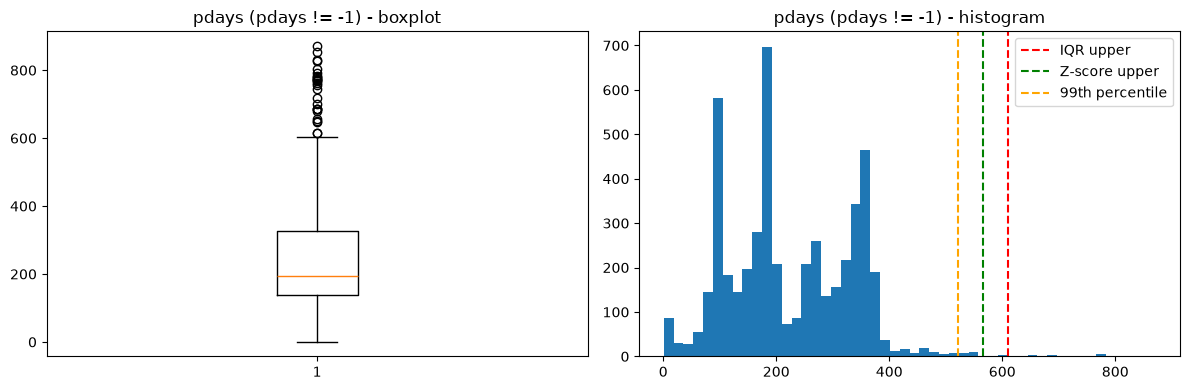

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(p)
axes[0].set_title('pdays (pdays != -1) - boxplot')
axes[1].hist(p, bins=50)
axes[1].axvline(iqr_hi, color='red', linestyle='--', label='IQR upper')
axes[1].axvline(z_hi, color='green', linestyle='--', label='Z-score upper')
axes[1].axvline(pct_hi, color='orange', linestyle='--', label='99th percentile')
axes[1].set_title('pdays (pdays != -1) - histogram')
axes[1].legend()
plt.tight_layout()
plt.show()

#### pdays 이상치 판단
- 이전 연락 고객(Train 4,938건)을 대상으로 탐지한 결과 IQR 27건(0.55%, 609.9일 초과), Z-score 31건(0.63%, 565.3일 초과), 백분위수 99건(2.00%, 7.4일 미만 또는 521.0일 초과)이 탐지됨.
- IQR과 Z-score는 약 570~610일 이상으로 비슷한 기준을 보여 서로의 결과를 뒷받침함. 분포의 왜도가 0.64로 크게 치우치지 않아 Z-score를 적용해도 무리가 없음.
- 백분위수는 정의상 항상 약 2%를 잘라내므로, 이상치 존재 여부를 판단하기보다 클리핑 기준을 정하는 용도로 활용함.
- 최대값 871일(약 2.4년)은 현실적으로 가능한 값이고, 값이 연속적으로 분포하며, 이상치 구간의 가입률(25~29%)도 정상 구간(약 22.6%)과 큰 차이가 없음.
- 결론: pdays는 삭제하지 않고 유지하며, Logistic Regression 적용 시 IQR 또는 Z-score 상한에서 클리핑을 검토함.
- 참고로 -1을 포함한 전체 데이터에 Z-score를 적용하면 1,022건이 탐지되는데, 이는 이전 연락 이력이 있다는 이유만으로 잡힌 결과이므로 의미가 없음.

#### 이상치 전처리
- IQR(1.5배) 기준으로 Train 데이터(26,931건)를 점검한 결과 age 287건(1.07%), balance 2,829건(10.50%), campaign 1,821건(6.76%)의 이상치가 탐지되었으나, 도메인 규칙상 오류값은 없어 모두 실제로 존재할 수 있는 극단값으로 판단하였다. age는 18~93세로 현실적이며, IQR 상한(70.5세)을 넘는 고객의 가입률이 44.3%로 정상 범위(11.3%)보다 높아 유지하였다. balance의 음수 잔고(8.31%)와 고액 잔고(최대 98,417)도 실제 가능한 값이므로 유지하되, 분포가 크게 치우쳐 있어 Logistic Regression 적용 시 로그 변환을 검토한다. campaign은 IQR 상한(6회)을 넘는 고객의 가입률이 5.1%로 정상 범위(12.2%)보다 낮아 유의미한 정보로 보고 유지하되, Logistic Regression 적용 시 클리핑을 검토한다. day는 이상치가 없었다.
- previous는 최대값 275가 다음으로 큰 값(58)과 크게 동떨어져 있어 입력 오류로 판단하고, 100 초과 값을 오류로 간주하는 규칙을 세 데이터셋에 동일하게 적용하여 삭제하였다(Train 1건, 삭제 후 Train 26,930건).
- pdays는 -1(이전 연락 없음)을 제외한 이전 연락 고객만을 대상으로 IQR, Z-score, 백분위수 세 가지 방법으로 탐지한 결과 각각 27건(0.55%), 31건(0.63%), 99건(2.00%)이 탐지되었다. 그러나 최대값 871일은 현실적으로 가능한 범위이며 값이 연속적으로 분포하고, 이상치 구간의 가입률도 정상 구간과 큰 차이가 없어 삭제하지 않고 유지하였다.

# 2. 베이스라인
- Baseline 정의: 불균형 처리 없음(클래스 가중치·Sampling 없음), 기본 하이퍼파라미터, 분류 임계값 0.5
- 모델 선정 이유
  - Logistic Regression: 가장 단순한 기준선이며, 계수로 각 변수가 가입 가능성을 높이는지 낮추는지 방향까지 해석 가능
  - Decision Tree: 규칙 기반으로 판단 과정을 이해하기 쉽고, 피처 중요도로 중요한 변수를 파악해 전처리 보완 방향을 정하는 용도
  - Dummy(모두 '미가입'으로 예측): Accuracy만으로는 평가할 수 없음을 보여주는 비교 기준선
- 평가 방식: Train으로 학습, Validation으로 평가 (Test는 최종 평가 전까지 사용하지 않음)

## 2-1. 베이스라인 라이브러리 불러오기

In [24]:
import time
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42

## 2-2. 전처리기
- 범주형 변수는 원-핫 인코딩(yes/no 변수는 0/1 한 칼럼), education은 순서형 인코딩(primary < secondary < tertiary)
- Logistic Regression에만 StandardScaler 적용 (값의 크기를 그대로 계산에 쓰는 모델이므로). Decision Tree는 값의 순서로만 분기하므로 스케일링 불필요
- Pipeline 안에 전처리를 넣어 Train에서만 fit되고 Validation에는 같은 기준이 적용되도록 함

In [25]:
num_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
nom_cols = ['job', 'marital', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
edu_col  = ['education']
edu_order = [['primary', 'secondary', 'tertiary']]

def make_preprocessor(scale):
    num_step = StandardScaler() if scale else 'passthrough'
    return ColumnTransformer([
        ('num', num_step, num_cols),
        ('edu', OrdinalEncoder(categories=edu_order), edu_col),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), nom_cols)
    ])

def make_pipeline(model, scale):
    return Pipeline([('prep', make_preprocessor(scale)), ('model', model)])

## 2-3. 평가 함수
| 역할 | 지표 |
|---|---|
| 모델 순위 비교 (주 지표) | PR-AUC (무작위 예측 시 기준선 = 가입 비율 0.117) |
| 보조 순위 지표 | ROC-AUC |
| 실제 분류 성능 (임계값 0.5) | Recall, Precision, F1 |
| 오류 구조 | Confusion Matrix (TP, FP, FN, TN) |
| 참고용 | Accuracy |

In [26]:
def evaluate(name, pipe, X_tr, y_tr, X_ev, y_ev, threshold=0.5):
    start = time.time()
    pipe.fit(X_tr, y_tr)
    train_time = time.time() - start

    proba = pipe.predict_proba(X_ev)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_ev, pred).ravel()

    return {
        '모델': name,
        'PR-AUC':    round(average_precision_score(y_ev, proba), 4),
        'ROC-AUC':   round(roc_auc_score(y_ev, proba), 4),
        'Recall':    round(recall_score(y_ev, pred, zero_division=0), 4),
        'Precision': round(precision_score(y_ev, pred, zero_division=0), 4),
        'F1':        round(f1_score(y_ev, pred, zero_division=0), 4),
        'Accuracy':  round(accuracy_score(y_ev, pred), 4),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
        '학습 시간(초)': round(train_time, 2),
    }, proba

## 2-4. 모델 학습 및 Validation 평가

In [27]:
baseline_models = {
    'Dummy (all no)':      (DummyClassifier(strategy='most_frequent'), False),
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
    'Decision Tree':       (DecisionTreeClassifier(random_state=RANDOM_STATE), False),
}

results, probas, fitted = [], {}, {}
for name, (model, scale) in baseline_models.items():
    pipe = make_pipeline(model, scale)
    res, proba = evaluate(name, pipe, X_train, y_train, X_val, y_val)
    results.append(res); probas[name] = proba; fitted[name] = pipe

pd.set_option('display.max_columns', 20)
baseline_df = pd.DataFrame(results).set_index('모델')
print('Val 가입 비율 (PR-AUC 기준선):', round(y_val.mean(), 4))
baseline_df

Val 가입 비율 (PR-AUC 기준선): 0.117


,PR-AUC,ROC-AUC,Recall,Precision,F1,Accuracy,TP,FP,FN,TN,학습 시간(초)
모델,,,,,,,,,,,
Dummy (all no),0.1170,0.5000,0.0000,0.0000,0.0000,0.8830,0,0,1051,7935,0.03
Logistic Regression,0.4034,0.7636,0.1798,0.6385,0.2806,0.8922,189,107,862,7828,0.07
Decision Tree,0.1781,0.6154,0.3340,0.3000,0.3161,0.8310,351,819,700,7116,0.72


#### 베이스라인 결과 해석
- Accuracy는 의미가 없음: Dummy가 가입 고객을 한 명도 찾지 못하는데도(Recall 0) Accuracy 88.3%이며, LR은 89.2%로 Dummy와 1%p 차이에 불과하고 Decision Tree는 83.1%로 오히려 Dummy보다 낮음.
- PR-AUC: LR 0.403으로 기준선(0.117) 대비 약 3.4배이지만, Decision Tree는 0.178로 기준선보다 조금 나은 수준에 그침.
- ROC-AUC는 실제보다 좋아 보임: LR 0.764로 높아 보이지만 다수 클래스(미가입)를 잘 맞히는 것에도 점수를 주기 때문이며, 불균형 데이터에서는 PR-AUC가 더 정직함.
- LR은 '가입' 예측을 매우 조심스럽게 함: Precision 63.9%로 '가입'이라고 예측하면 꽤 맞지만 Recall이 18.0%에 그쳐, 실제 가입 고객 1,051명 중 862명을 놓침. 다수 클래스에 끌린 불균형 데이터의 전형적인 모습임.
- Decision Tree는 반대로 과감함: Recall 33.4%로 가입 고객을 더 많이 찾았지만 Precision이 30.0%로 떨어지고, 괜히 '가입'으로 예측한 고객(FP)이 819명으로 LR(107명)의 약 7.7배임.

## 2-5. 과적합 확인 (Train vs Validation)

In [28]:
fit_check = pd.DataFrame({
    name: {'Train PR-AUC': round(average_precision_score(y_train, fitted[name].predict_proba(X_train)[:, 1]), 4),
           'Val PR-AUC':   round(average_precision_score(y_val,   probas[name]), 4)}
    for name in ['Logistic Regression', 'Decision Tree']
}).T
display(fit_check)

dt_model = fitted['Decision Tree'].named_steps['model']
print('Decision Tree 깊이:', dt_model.get_depth(), '| 잎(최종 노드) 수:', dt_model.get_n_leaves())
print('Decision Tree가 Validation에 준 확률 값의 종류:', np.unique(probas['Decision Tree']))

,Train PR-AUC,Val PR-AUC
Logistic Regression,0.4108,0.4034
Decision Tree,1.0000,0.1781


Decision Tree 깊이: 40 | 잎(최종 노드) 수: 3533
Decision Tree가 Validation에 준 확률 값의 종류: [0. 1.]


#### 과적합 해석
- Logistic Regression: Train과 Val의 PR-AUC가 비슷해(0.411 vs 0.403) 과적합이 없음.
- Decision Tree: Train PR-AUC 1.0, Val 0.178로 Train을 거의 외운 심한 과적합 상태. 깊이 제한이 없는 기본 설정이라 깊이 40, 잎 3,533개까지 자라 Train 고객 거의 하나하나에 맞춘 규칙을 만들었음.
- 잎마다 고객이 거의 한 명씩만 남아 확률이 0 또는 1로만 나옴. 확률이 촘촘하지 않아 임계값을 조정할 여지가 없고, 이 때문에 PR-AUC가 낮게 나옴.
- 이후 튜닝 단계에서 max_depth, min_samples_leaf 등으로 트리 크기를 제한하면 크게 개선될 것으로 예상됨. 또한 이 과적합은 아래 Decision Tree 기본 피처 중요도 해석에도 영향을 줌.

## 2-6. Confusion Matrix

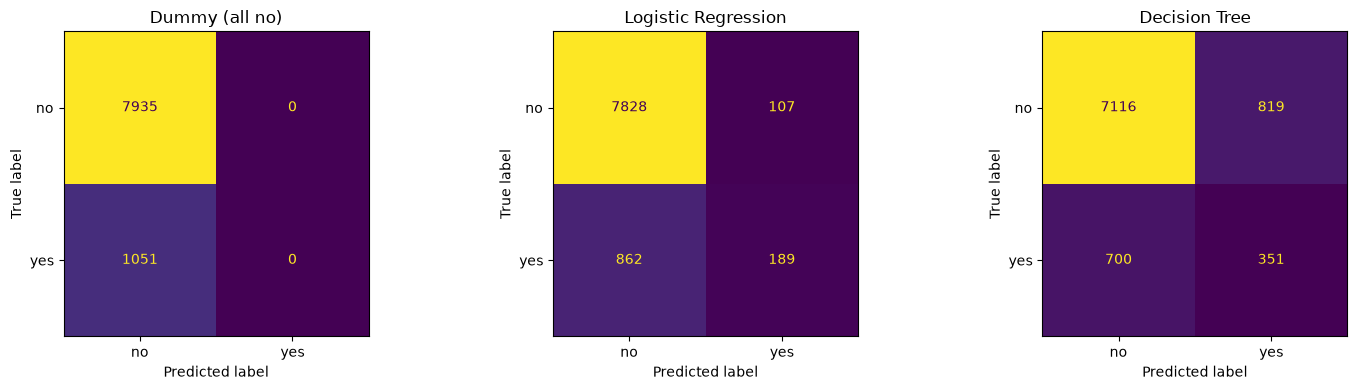

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ['Dummy (all no)', 'Logistic Regression', 'Decision Tree']):
    pred = (probas[name] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_val, pred),
                           display_labels=['no', 'yes']).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout()
plt.show()

#### Confusion Matrix 해석
| 모델 | TP (찾은 가입 고객) | FP (괜히 전화할 고객) | FN (놓친 가입 고객) | TN |
|---|---|---|---|---|
| Dummy | 0 | 0 | 1,051 | 7,935 |
| Logistic Regression | 189 | 107 | 862 | 7,828 |
| Decision Tree | 351 | 819 | 700 | 7,116 |

- 두 모델 모두 FN이 TP보다 많음. LR은 찾아낸 가입 고객보다 놓친 고객이 약 4.6배, Decision Tree는 약 2배.
- Decision Tree는 LR보다 가입 고객을 162명 더 찾았지만(TP 189 → 351), 괜히 전화할 고객은 712명 늘었음(FP 107 → 819). 가입 고객을 더 찾으려 하면 오판도 늘어나는 Precision–Recall Trade-off가 나타나며, Decision Tree는 과적합으로 그 대가가 특히 큼.
- 마케팅 관점에서 FN은 '놓친 매출', FP는 '헛걸음한 통화 비용'이며, 어느 쪽을 더 줄일지는 비즈니스 비용 분석 단계에서 결정함.

## 2-7. Precision-Recall 곡선
- 임계값을 1에서 0으로 낮춰 가며 그린 곡선. 오른쪽 위에 가까울수록 좋은 모델이며, 곡선 아래 면적이 PR-AUC.
- 회색 점선은 무작위 예측 수준(가입 비율 0.117).

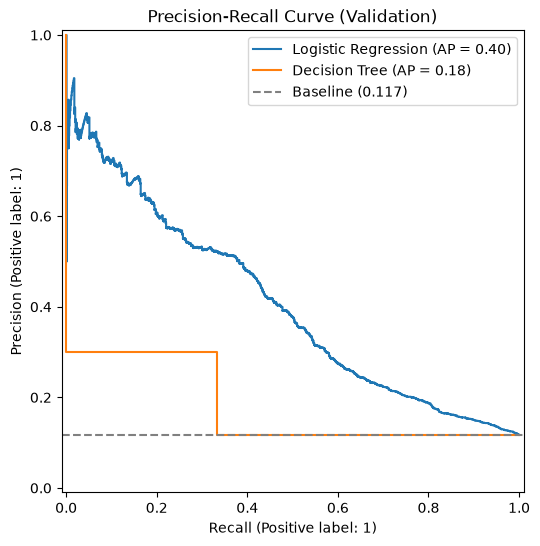

가입 확률 0.5 이상을 받은 고객 비율 - LR: 0.033


,목표 Recall,Precision,임계값
0,0.3,0.53,0.31
1,0.5,0.38,0.16
2,0.7,0.22,0.10


In [30]:
fig, ax = plt.subplots(figsize=(8, 6))
for name in ['Logistic Regression', 'Decision Tree']:
    PrecisionRecallDisplay.from_predictions(y_val, probas[name], name=name, ax=ax)
ax.axhline(y_val.mean(), color='gray', linestyle='--', label=f'Baseline ({y_val.mean():.3f})')
ax.set_title('Precision-Recall Curve (Validation)')
ax.legend(loc='upper right')
plt.show()

# Logistic Regression 곡선 위 주요 지점: 같은 Recall에서의 Precision과 그때의 임계값
p, r, t = precision_recall_curve(y_val, probas['Logistic Regression'])
rows = []
for target in [0.3, 0.5, 0.7]:
    i = np.where(r >= target)[0][-1]
    rows.append([target, round(p[i], 2), round(t[min(i, len(t) - 1)], 2)])
print('가입 확률 0.5 이상을 받은 고객 비율 - LR:', round((probas['Logistic Regression'] >= 0.5).mean(), 3))
pd.DataFrame(rows, columns=['목표 Recall', 'Precision', '임계값'])

#### PR 곡선 해석
- Logistic Regression은 매끄러운 곡선을 그림. 확률이 촘촘해서 임계값을 조정하며 Recall과 Precision 사이에서 원하는 지점을 고를 수 있음.
- 임계값 0.5는 이 데이터에 너무 높음: LR이 가입 확률 0.5 이상을 준 고객은 3.3%에 불과해 Recall이 낮게 나옴. 임계값을 0.16으로 낮추면 Recall 50%에서 Precision 38%를 얻을 수 있음.
- 다만 Recall 70%를 얻으려면 Precision이 22%까지 떨어져, 약 4~5명에게 전화해야 1명이 가입하는 수준이 됨. 어느 지점을 고를지가 이후 단계의 핵심 결정임.
- Decision Tree는 곡선이 아니라 꺾인 선 하나로 나타남. 확률이 0과 1뿐이라 가능한 지점이 (Recall 33.4%, Precision 30.0%) 하나밖에 없고, 임계값을 바꿔도 결과가 달라지지 않음. 기본 설정의 Decision Tree는 임계값 조정으로 개선할 수 없는 구조임.

## 2-8. 피처 중요도 (Decision Tree 기본 중요도 vs Permutation Importance)
- Decision Tree 기본 중요도: Train 데이터에서 트리를 나눌 때 얼마나 많이 쓰였는지. 값이 다양한 연속형 변수를 과대평가하는 경향이 있고, 과적합된 트리에서는 이 왜곡이 더 커짐.
- Permutation Importance: Validation 데이터에서 변수 하나를 무작위로 섞었을 때 PR-AUC가 얼마나 떨어지는지. 실제 예측 기여도를 더 정직하게 보여줌.
- Pipeline 전체에 적용해, 원-핫으로 쪼개진 칼럼도 원래 변수 단위로 평가함.

In [31]:
dt_pipe = fitted['Decision Tree']
lr_pipe = fitted['Logistic Regression']

# (1) Decision Tree 기본 중요도 → 원-핫 칼럼을 원래 변수로 합산
feat_names = [n.split('__', 1)[1] for n in dt_pipe.named_steps['prep'].get_feature_names_out()]
def to_original(name):
    for c in num_cols + edu_col + nom_cols:
        if name == c or name.startswith(c + '_'):
            return c
mdi = (pd.Series(dt_pipe.named_steps['model'].feature_importances_,
                 index=[to_original(n) for n in feat_names])
       .groupby(level=0).sum())

# (2) Permutation Importance (Validation, PR-AUC 감소량)
perm_dt = permutation_importance(dt_pipe, X_val, y_val, scoring='average_precision',
                                 n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_lr = permutation_importance(lr_pipe, X_val, y_val, scoring='average_precision',
                                 n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)

importance_df = pd.DataFrame({
    'DT 기본 중요도(Train)': mdi,
    'DT Permutation(Val)': pd.Series(perm_dt.importances_mean, index=X_val.columns),
    'LR Permutation(Val)': pd.Series(perm_lr.importances_mean, index=X_val.columns),
}).round(4).sort_values('DT Permutation(Val)', ascending=False)
importance_df

,DT 기본 중요도(Train),DT Permutation(Val),LR Permutation(Val)
month,0.1019,0.0373,0.0789
contact,0.0209,0.0264,0.0640
day,0.1180,0.0208,0.0002
poutcome,0.1069,0.0203,0.1308
pdays,0.0515,0.0136,0.0002
age,0.1428,0.0113,0.0004
marital,0.0253,0.0062,0.0029
balance,0.2175,0.0048,0.0022
housing,0.0153,0.0045,0.0235
education,0.0240,0.0025,0.0034


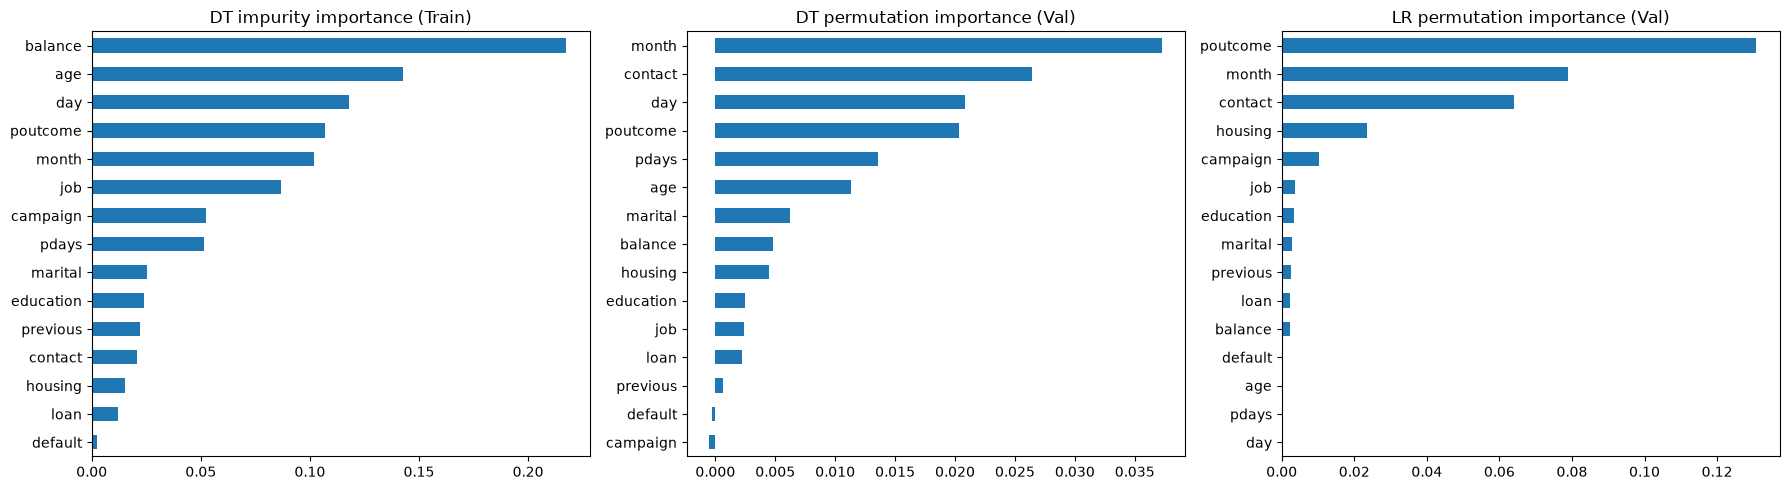

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
importance_df['DT 기본 중요도(Train)'].sort_values().plot(kind='barh', ax=axes[0], title='DT impurity importance (Train)')
importance_df['DT Permutation(Val)'].sort_values().plot(kind='barh', ax=axes[1], title='DT permutation importance (Val)')
importance_df['LR Permutation(Val)'].sort_values().plot(kind='barh', ax=axes[2], title='LR permutation importance (Val)')
plt.tight_layout()
plt.show()

#### 피처 중요도 해석
- 두 방식의 순위가 크게 다름: Decision Tree 기본 중요도 1위인 balance(0.218)는 Permutation에서 0.005로 거의 영향이 없음. age(0.143), day(0.118)도 기본 중요도는 높지만 Permutation은 낮음. 값이 다양해서 과적합된 트리가 Train 고객을 구분하는 데 자주 썼을 뿐, 실제 예측에는 도움이 크지 않은 것으로 판단됨.
- 실제로 중요한 변수는 month, contact, poutcome: Decision Tree Permutation 상위는 month(0.037), contact(0.026), day(0.021), poutcome(0.020) 순이고, LR Permutation 상위는 poutcome(0.131), month(0.079), contact(0.064) 순. 서로 다른 방식의 두 모델에서 month, contact, poutcome이 공통으로 상위에 있어 신뢰할 수 있음.
- day는 Decision Tree에서만 3위이고 LR에서는 거의 0임. 날짜(1~31일)와 가입 여부가 직선적인 관계가 아니어서 LR은 활용하지 못하고, 트리는 특정 날짜 구간으로 나눠 활용한 것으로 보임. 다만 과적합된 트리의 결과라 추가 확인이 필요함.
- 기여도가 매우 작은 변수: education(0.003), job(0.002), balance(0.005), campaign(−0.001). education 대체나 balance 이상치 처리를 더 세밀하게 다듬어도 성능 차이는 작을 것으로 예상됨.
- Decision Tree는 과적합 상태라 Permutation 값 자체가 LR보다 작고 불안정할 수 있으므로, 두 모델에서 공통으로 나타난 변수를 중심으로 해석함. 보고서에는 Permutation Importance를 기준으로 사용함.

## 2-9. Logistic Regression 계수 (영향의 방향)
- 양수: 가입 가능성을 높이는 쪽 / 음수: 가입 가능성을 낮추는 쪽

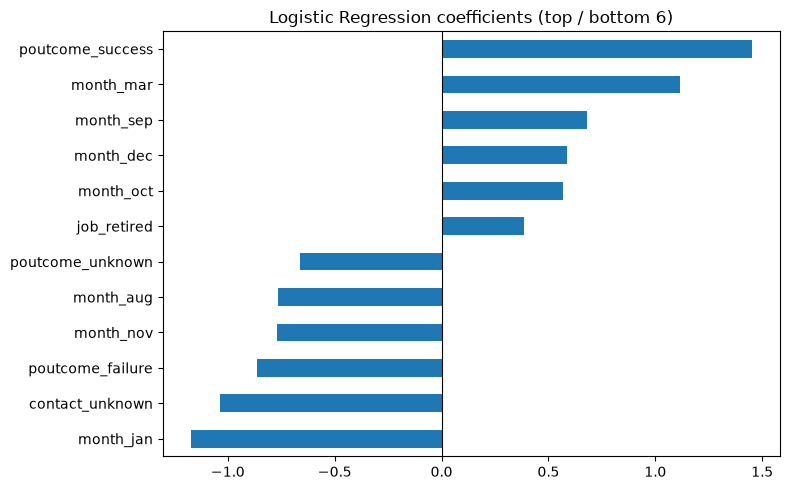

month_jan          -1.173
contact_unknown    -1.038
poutcome_failure   -0.864
month_nov          -0.770
month_aug          -0.763
poutcome_unknown   -0.663
job_retired         0.385
month_oct           0.570
month_dec           0.585
month_sep           0.679
month_mar           1.114
poutcome_success    1.452
dtype: float64

In [33]:
lr_feat_names = [n.split('__', 1)[1] for n in lr_pipe.named_steps['prep'].get_feature_names_out()]
coef = pd.Series(lr_pipe.named_steps['model'].coef_[0], index=lr_feat_names).sort_values()
top_coef = pd.concat([coef.head(6), coef.tail(6)]).round(3)

top_coef.plot(kind='barh', figsize=(8, 5), title='Logistic Regression coefficients (top / bottom 6)')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()
top_coef

#### LR 계수 해석
- 가입 가능성을 높이는 쪽: poutcome_success(+1.45)가 가장 강하고, month_mar(+1.11), sep(+0.68), dec(+0.59), oct(+0.57) 순. 이전 캠페인에서 가입한 고객과 3·9·10·12월 연락이 가입과 관련이 큼.
- 가입 가능성을 낮추는 쪽: month_jan(−1.17), contact_unknown(−1.04), poutcome_failure(−0.86), month_nov(−0.77), aug(−0.76), poutcome_unknown(−0.66).
- Permutation 결과와 마찬가지로 month, poutcome, contact 관련 항목이 계수 상·하위를 차지함.

## 2-10. 피처 중요도 확인 시점 검증
- 피처 중요도를 지금(Baseline) 확인할지, 불균형 처리 후 확인할지 판단하기 위해 Class Weight를 적용한 모델과 상위 변수를 비교함.
- 상위 변수가 같다면 지금 결과로 전처리를 확정해도 안전함.

In [34]:
perm_cmp = {}
for name, model, scale in [
    ('LR', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True),
    ('LR + Class Weight', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'), True),
    ('DT', DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    ('DT + Class Weight', DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced'), False),
]:
    pipe = make_pipeline(model, scale).fit(X_train, y_train)
    pi = permutation_importance(pipe, X_val, y_val, scoring='average_precision',
                                n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    perm_cmp[name] = pd.Series(pi.importances_mean, index=X_val.columns)

perm_cmp = pd.DataFrame(perm_cmp)
print('Permutation Importance 순위 (DT 기준 상위 6개)')
perm_cmp.rank(ascending=False).astype(int).sort_values('DT').head(6)

Permutation Importance 순위 (DT 기준 상위 6개)


,LR,LR + Class Weight,DT,DT + Class Weight
month,2,2,1,1
contact,3,3,2,3
day,14,13,3,5
poutcome,1,1,4,4
pdays,15,14,5,2
age,12,15,6,8


#### 확인 시점 해석
- Logistic Regression은 Class Weight 적용 전후에 상위 3개(poutcome, month, contact)의 순위가 완전히 동일함.
- Decision Tree는 month가 적용 전후 모두 1위이고, contact·poutcome도 상위 4위 안에 유지됨. 다만 pdays가 5위에서 2위로 올라가는 등 LR보다 순위 변동이 있는데, 이는 과적합된 단일 트리라 결과가 불안정하기 때문으로 보임.
- 피처 중요도는 '데이터 안에서 가입 여부를 알려주는 신호가 어디 있는가'를 보여주며, 불균형 처리는 모델의 판단 기준(과감함)을 바꿀 뿐 핵심 신호의 위치는 크게 바꾸지 않음.
- 결론: 핵심 변수(month, poutcome, contact)는 불균형 처리 전후에 유지되므로, 지금(Baseline) 결과로 전처리를 확정한 뒤 불균형 처리 실험을 진행함. 불균형 실험 후에 전처리를 바꾸면 모든 실험을 다시 해야 하므로 전처리는 먼저 확정하는 것이 효율적임. 최종 모델의 피처 중요도는 모델 선정 후 설명 목적으로 다시 확인함.

## 2-11. 베이스라인 종합 및 다음 단계
#### 종합
- 불균형 처리를 하지 않은 Baseline에서 Logistic Regression은 PR-AUC 0.403으로 기준선(0.117) 대비 약 3.4배의 성능을 보였으나, 임계값 0.5에서는 Recall이 18.0%에 그쳐 실제 가입 고객의 82%를 놓쳤음.
- Decision Tree는 기본 설정에서 깊이 40까지 자라 Train PR-AUC 1.0의 심한 과적합을 보였고, 확률을 0과 1로만 출력해 PR-AUC가 0.178에 그쳤음. Recall(33.4%)은 LR보다 높지만 FP가 819건으로 Precision이 30.0%까지 떨어졌음.
- Accuracy는 Dummy(88.3%)와 거의 같거나 더 낮아 평가 지표로 의미가 없으며, PR-AUC와 Recall·Precision 중심의 평가가 필요함이 확인됨.
- 피처 중요도는 Decision Tree 기본 중요도가 연속형 변수를 과대평가하여 Permutation Importance로 보완하였고, 두 모델 모두 month, poutcome, contact가 가장 중요한 변수였으며 balance·job·education의 기여도는 매우 작았음.

#### 전처리 재점검 항목 (중요 변수 기준)
1. contact unknown과 month의 관계: contact unknown이 5·6월에 집중되어 있어, contact_unknown의 강한 음의 계수(−1.04)가 '연락 방식 미상' 자체의 정보인지, 가입률이 낮은 5·6월이라는 정보를 중복으로 담고 있는지 확인 필요.
2. month와 수집 시기의 관계: 데이터가 2008~2010년에 걸쳐 있고 시기별 가입률 차이가 커서, month가 계절 효과가 아닌 '수집 시기'를 대신 나타내는지 확인 필요 (무작위 분할 시 성능이 실제보다 높게 보일 가능성).
3. poutcome·pdays·previous의 중복 정보: 세 변수 모두 '이전 연락 없음'을 담고 있어, 이전 연락 여부 플래그 생성이나 poutcome의 other 범주 처리 검토.
4. day의 활용: Decision Tree에서만 중요하게 나타나, 특정 날짜 구간의 효과인지 과적합의 결과인지 확인 필요.
5. 추가 처리가 필요 없는 부분: education, job, balance는 예측 기여도가 작아 현재 전처리 수준으로 마무리함.

#### 다음 단계
- 위 재점검 결과로 전처리를 확정한 뒤, 불균형 처리(Class Weight → Random Under Sampling → SMOTE, 비율 1:3 / 1:2 / 1:1) 실험과 다른 모델(Random Forest, KNN, Gradient Boosting, XGBoost, LightGBM, AdaBoost, Stacking) 비교를 진행함.
- Decision Tree는 max_depth, min_samples_leaf 등으로 과적합을 줄인 버전과 함께 비교함.

In [35]:
baseline_df.to_csv('baseline_val.csv')
importance_df.to_csv('baseline_importance.csv')
print('저장 완료: baseline_val.csv, baseline_importance.csv')

저장 완료: baseline_val.csv, baseline_importance.csv


# 3. 불균형 처리
- 목적: 클래스 불균형(가입 11.7% : 미가입 88.3%, 약 1 : 7.5)을 처리했을 때 성능이 어떻게 달라지는지, 개선 효과와 부작용을 함께 확인함.
- 대상 모델: 베이스라인과 같은 Logistic Regression, Decision Tree (다른 모델들은 4장 모델링에서 비교)
- 불균형 처리의 효과만 비교하기 위해 베이스라인과 같은 전처리를 사용하고, LR·KNN용 이상치 클리핑은 4장 모델링에서 적용함
- 처리 방법 8가지: 처리 없음, Class Weight, Random Under Sampling(1:3, 1:2, 1:1), SMOTE(1:3, 1:2, 1:1)
- 비율 정의: 가입 : 미가입. sampling_strategy에는 '가입 수 ÷ 미가입 수'를 넣음 (1:3 = 0.333, 1:2 = 0.5, 1:1 = 1.0)
- 누수 방지 원칙
  - Sampling은 imblearn Pipeline 안에 넣어 Train에만 적용하고, Validation은 실제 분포(가입 11.7%)를 그대로 유지함
  - Class Weight는 데이터를 바꾸지 않고 모델 설정으로 적용함
- 평가 기준: Accuracy, Precision, Recall, F1 네 지표를 모두 확인하고, 네 지표의 평균 순위로 가장 좋은 조합을 선택함 (PR-AUC는 참고용으로 함께 기록)

## 3-1. 불균형 처리 라이브러리 불러오기

In [36]:
from imblearn.pipeline import Pipeline as ImbPipeline       # Sampling을 Pipeline 안에 넣기 위해 imblearn 사용
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTENC

## 3-2. 평가 방식: 네 지표의 평균 순위
- Accuracy, Precision, Recall, F1을 각각 높은 순서로 순위를 매기고, 네 순위의 평균을 계산함. 평균 순위가 작을수록 여러 지표를 골고루 잘하는 조합임.
- 지표별 1등 횟수로 고르지 않는 이유
  - Precision·Accuracy와 Recall은 서로 반대로 움직임. '가입'이라고 조심스럽게 말하면 Precision·Accuracy가 높고, 과감하게 말하면 Recall이 높아 한 조합이 모두 1등을 하기 어려움.
  - 1등 횟수는 차이의 크기를 반영하지 못하고, 지표마다 1등이 다르면 동점이 됨.
- 네 지표 모두 임계값 0.5 기준이므로, 임계값을 바꾸면 순위도 달라질 수 있음.

In [60]:
# 순위를 매길 네 지표 (모두 임계값 0.5 기준)
RANK_METRICS = ['Accuracy', 'Precision', 'Recall', 'F1']

def add_avg_rank(df, metrics=RANK_METRICS):
    """
    결과표(df)에 '평균 순위' 칼럼을 추가하는 함수

    예시) 조합 A가 Accuracy 3등, Precision 5등, Recall 2등, F1 1등이면
         평균 순위 = (3 + 5 + 2 + 1) / 4 = 2.75
         → 평균 순위가 작을수록 네 지표를 골고루 잘하는 조합
    """
    df = df.copy()                                   # 원본 표를 건드리지 않도록 복사

    # df[metrics].rank(ascending=False)
    #   : 각 지표 칼럼마다 "값이 클수록 1등"이 되도록 순위를 매김
    #     (ascending=False → 내림차순, 즉 큰 값이 1등)
    # .mean(axis=1)
    #   : 한 행(조합) 안에서 네 지표의 순위를 평균 냄
    #     (axis=1 → 가로 방향으로 평균)
    df['평균 순위'] = df[metrics].rank(ascending=False).mean(axis=1).round(2)
    return df

## 3-3. 불균형 처리 방법 정의
- Random Under Sampling(RUS): 미가입 고객을 무작위로 줄여 비율을 맞춤. 데이터가 줄어 학습이 빠르지만 미가입 고객 정보를 버림.
- SMOTE: 가입 고객 사이에 가짜 가입 고객을 만들어 늘림. 정보를 버리지 않지만 실제로 없는 고객이 생김.
  - 일반 SMOTE는 원-핫 칼럼 사이에서 'job_admin = 0.4'처럼 존재할 수 없는 값을 만들기 때문에, 범주형 변수를 고려하는 SMOTENC를 사용함. SMOTENC는 범주형은 실제 있는 값 중에서 고르고, 수치형만 중간값을 만듦.
- Class Weight: 데이터는 그대로 두고, 가입 고객을 틀렸을 때 벌점을 더 크게 줌 ('balanced' = 클래스 비율의 역수만큼).

In [61]:
# SMOTENC에게 "이 칼럼들은 범주형이야"라고 알려줄 목록
# nom_cols, edu_col은 2장에서 정의한 칼럼 목록
cat_all = nom_cols + edu_col

# ─────────────────────────────────────────────────────────────
# 불균형 처리 방법 8가지를 딕셔너리로 준비
#   키   : 이름 (결과표에 표시용)
#   값   : 실제 도구 (또는 표시용 값)
# ⚠️ 여기서는 "도구를 만들기만" 할 뿐, 아직 데이터에 적용하지 않음
#    실제 적용은 3-4에서 pipe.fit()을 할 때 일어남
# ─────────────────────────────────────────────────────────────
methods = {
    '처리 없음': None,                 # None → 아무 처리도 안 함
    'Class Weight': 'class_weight',   # 문자열 표시 → 데이터는 그대로, 모델 설정으로 처리
}

# RUS(언더샘플링) 3가지 비율 추가
# sampling_strategy = 가입 수 ÷ 미가입 수 (샘플링 후 목표 비율)
#   1:3 → 1/3 = 0.333  (가입 1명당 미가입 3명이 되도록 미가입을 줄임)
#   1:2 → 1/2 = 0.5
#   1:1 → 1.0          (가입과 미가입을 같은 수로)
for label, ratio in [('1:3', 1/3), ('1:2', 1/2), ('1:1', 1.0)]:
    methods[f'RUS {label}'] = RandomUnderSampler(
        sampling_strategy=ratio,
        random_state=RANDOM_STATE      # 같은 고객이 뽑히도록 고정 → 재현 가능, 모델 간 공정 비교
    )

# SMOTE(오버샘플링) 3가지 비율 추가
#   같은 비율이라도 SMOTE는 미가입은 그대로 두고 가입을 "늘려서" 맞춤
for label, ratio in [('1:3', 1/3), ('1:2', 1/2), ('1:1', 1.0)]:
    methods[f'SMOTE {label}'] = SMOTENC(
        categorical_features=cat_all,  # 범주형 칼럼 이름 목록
        sampling_strategy=ratio,
        random_state=RANDOM_STATE
    )

# ─────────────────────────────────────────────────────────────
# (확인용) 각 샘플링을 적용하면 Train 크기가 어떻게 바뀌는지 미리 보기
# 실제 학습에는 쓰지 않고, 표로 확인만 하는 코드
# ─────────────────────────────────────────────────────────────
size_rows = [['처리 없음 / Class Weight', len(y_train), int(y_train.sum()), int((y_train == 0).sum())]]

for name, sampler in methods.items():
    if sampler not in (None, 'class_weight'):          # 실제 샘플링 도구인 것만
        # fit_resample: 샘플링을 실제로 실행해서 바뀐 X, y를 돌려줌
        #   여기서는 크기만 보려고 y_res만 사용 (_는 "안 쓰는 값"이라는 관례 표기)
        _, y_res = sampler.fit_resample(X_train, y_train)
        size_rows.append([name, len(y_res), int(y_res.sum()), int((y_res == 0).sum())])

pd.DataFrame(size_rows, columns=['방법', 'Train 전체', '가입', '미가입']).set_index('방법')

,Train 전체,가입,미가입
방법,,,
처리 없음 / Class Weight,26930,3151,23779
RUS 1:3,12604,3151,9453
RUS 1:2,9453,3151,6302
RUS 1:1,6302,3151,3151
SMOTE 1:3,31705,7926,23779
SMOTE 1:2,35668,11889,23779
SMOTE 1:1,47558,23779,23779


#### 데이터 크기 변화 해석
- 원래 Train: 26,930건 (가입 3,151 : 미가입 23,779)
- RUS는 미가입 고객을 줄임: 1:3에서 12,604건, 1:1에서는 6,302건으로 원래의 약 23%만 남음. 미가입 고객 20,628명의 정보를 버리게 됨.
- SMOTE는 가입 고객을 늘림: 1:3에서 31,705건, 1:1에서는 47,558건으로 가짜 가입 고객 20,628명이 추가됨. 실제 가입 고객(3,151명)보다 가짜가 6.5배 많아짐.
- Validation은 이 처리와 무관하게 실제 분포(가입 11.7%)를 그대로 유지함.

## 3-4. 실험 실행 (모델 × 처리 방법)
- Pipeline 순서: [Sampling] → [인코딩·스케일링] → [모델(+Class Weight)]
- Decision Tree는 베이스라인과 같은 기본 설정으로 두어, 불균형 처리의 효과만 비교함.

In [62]:
def build_pipeline(model_name, method):
    """
    모델 이름과 처리 방법을 받아서, 알맞은 파이프라인을 '조립'하는 함수
    (조립만 할 뿐, 학습은 아직 안 함)

    조립 결과 예시)
      처리 없음    : [prep] → [model]
      Class Weight : [prep] → [model(class_weight='balanced')]
      RUS 1:3      : [sampler(RUS)] → [prep] → [model]
      SMOTE 1:3    : [sampler(SMOTENC)] → [prep] → [model]
    """
    # Class Weight 실험일 때만 'balanced', 나머지는 None(가중치 없음)
    cw = 'balanced' if method == 'class_weight' else None

    # 샘플링 도구가 들어온 경우만 sampler에 담음
    # (None이나 'class_weight' 문자열은 샘플링 도구가 아니므로 제외)
    sampler = method if method not in (None, 'class_weight') else None

    steps = []                                         # 파이프라인 단계를 순서대로 담을 리스트

    # 1단계: 샘플링 (있는 경우에만)
    #   ⚠️ 반드시 전처리보다 앞에 둠
    #   SMOTENC는 문자열 범주를 그대로 받아야 하므로 인코딩 전에 실행해야 함
    if sampler is not None:
        steps.append(('sampler', sampler))

    # 2단계: 전처리 + 3단계: 모델
    if model_name == 'Logistic Regression':
        steps += [('prep', make_preprocessor(True)),   # True → 스케일링 포함 (LR은 숫자 크기에 민감)
                  ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight=cw))]
    else:  # Decision Tree
        steps += [('prep', make_preprocessor(False)),  # False → 스케일링 없음 (트리는 순서만 봄)
                  ('model', DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight=cw))]

    # ('이름', 도구) 목록을 ImbPipeline으로 묶어서 반환
    return ImbPipeline(steps)


# ─────────────────────────────────────────────────────────────
# 실험 반복문: 모델 2개 × 처리 방법 8개 = 16번
# ─────────────────────────────────────────────────────────────
imb_rows = []      # 조합별 결과(지표)를 한 줄씩 쌓을 리스트
imb_probas = {}    # 조합별 Validation 예측 확률을 저장할 딕셔너리 (나중에 그래프용)

for model_name in ['Logistic Regression', 'Decision Tree']:
    for method_name, method in methods.items():        # 예: ('RUS 1:3', RandomUnderSampler 객체)

        # (1) 파이프라인 조립
        pipe = build_pipeline(model_name, method)

        # (2) 학습 + 예측 + 지표 계산 (2장에서 만든 evaluate 함수)
        #   evaluate 내부에서 일어나는 일:
        #     pipe.fit(X_train, y_train)
        #       → sampler가 있으면 이때 X_train에 샘플링 실행
        #       → 샘플링된 데이터를 prep으로 인코딩
        #       → model 학습
        #     pipe.predict_proba(X_val)
        #       → sampler는 건너뜀 (Validation은 원래 분포 그대로)
        #       → prep으로 인코딩 → model이 가입 확률 계산
        #     확률 0.5 이상이면 '가입'으로 보고 Accuracy, Precision, Recall, F1 계산
        res, proba = evaluate(f'{model_name} | {method_name}', pipe,
                              X_train, y_train, X_val, y_val)

        # (3) 나중에 표를 피벗하기 쉽도록 모델명, 처리 방법을 따로 기록
        res['모델명'] = model_name
        res['처리 방법'] = method_name

        # (4) 결과 저장
        imb_rows.append(res)
        imb_probas[(model_name, method_name)] = proba  # 키를 (모델, 방법) 튜플로 저장

# 결과 리스트 → 표로 변환하고 평균 순위 칼럼 추가
imb_df = add_avg_rank(pd.DataFrame(imb_rows))

show_cols = ['Accuracy', 'Precision', 'Recall', 'F1', '평균 순위', 'PR-AUC', 'TP', 'FP', 'FN', 'TN', '학습 시간(초)']
imb_df.set_index('모델')[show_cols]

,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,TP,FP,FN,TN,학습 시간(초)
모델,,,,,,,,,,,
Logistic Regression | 처리 없음,0.8922,0.6385,0.1798,0.2806,8.50,0.4034,189,107,862,7828,0.14
Logistic Regression | Class Weight,0.7522,0.2633,0.6223,0.3700,7.25,0.4015,654,1830,397,6105,0.14
Logistic Regression | RUS 1:3,0.8858,0.5189,0.3273,0.4014,5.75,0.4021,344,319,707,7616,0.09
Logistic Regression | RUS 1:2,0.8720,0.4491,0.4158,0.4318,4.75,0.4001,437,536,614,7399,0.07
Logistic Regression | RUS 1:1,0.7363,0.2518,0.6365,0.3608,8.00,0.3981,669,1988,382,5947,0.06
Logistic Regression | SMOTE 1:3,0.8840,0.5064,0.3368,0.4046,5.00,0.3822,354,345,697,7590,1.64
Logistic Regression | SMOTE 1:2,0.8534,0.3845,0.4215,0.4022,5.25,0.3730,443,709,608,7226,1.86
Logistic Regression | SMOTE 1:1,0.7251,0.2326,0.5871,0.3332,9.75,0.3632,617,2036,434,5899,2.46
Decision Tree | 처리 없음,0.8310,0.3000,0.3340,0.3161,9.75,0.1781,351,819,700,7116,1.46


#### 실험 결과 해석
| 처리 방법 | LR Accuracy | LR Precision | LR Recall | LR F1 | DT Accuracy | DT Precision | DT Recall | DT F1 |
|---|---|---|---|---|---|---|---|---|
| 처리 없음 | 0.892 | 0.639 | 0.180 | 0.281 | 0.831 | 0.300 | 0.334 | 0.316 |
| Class Weight | 0.752 | 0.263 | 0.622 | 0.370 | 0.835 | 0.308 | 0.329 | 0.318 |
| RUS 1:3 | 0.886 | 0.519 | 0.327 | 0.401 | 0.758 | 0.233 | 0.467 | 0.311 |
| RUS 1:2 | 0.872 | 0.449 | 0.416 | 0.432 | 0.718 | 0.214 | 0.525 | 0.304 |
| RUS 1:1 | 0.736 | 0.252 | 0.637 | 0.361 | 0.629 | 0.190 | 0.667 | 0.296 |
| SMOTE 1:3 | 0.885 | 0.511 | 0.341 | 0.409 | 0.795 | 0.257 | 0.400 | 0.313 |
| SMOTE 1:2 | 0.854 | 0.386 | 0.422 | 0.403 | 0.792 | 0.264 | 0.433 | 0.328 |
| SMOTE 1:1 | 0.725 | 0.233 | 0.586 | 0.333 | 0.777 | 0.255 | 0.470 | 0.330 |

- 아래 3-5 ~ 3-7에서 지표 변화와 평균 순위로 나누어 해석함.

## 3-5. 네 지표의 변화: 개선과 부작용

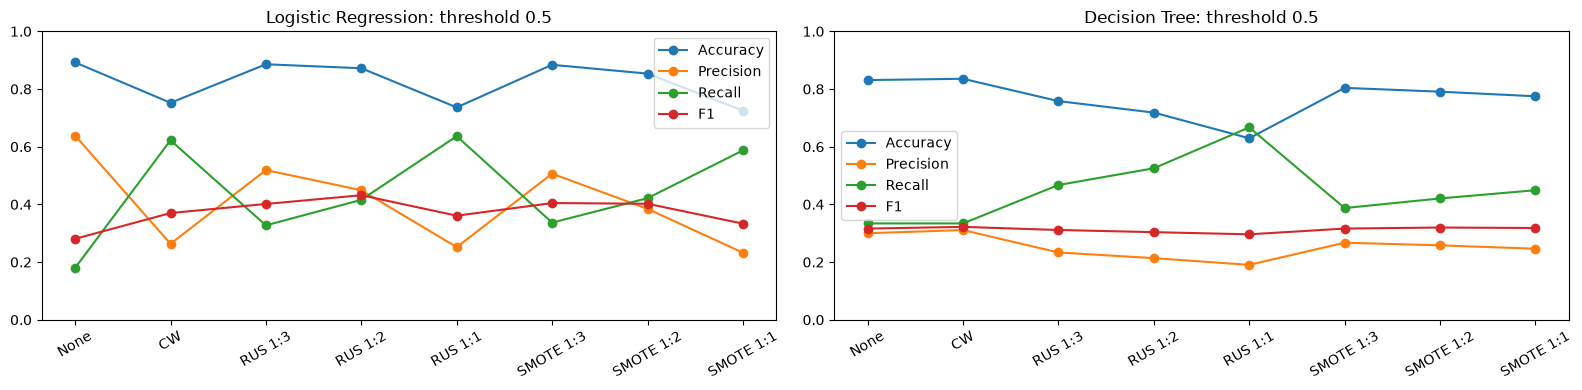

In [63]:
order = list(methods.keys())     # 그래프 x축 순서: 처리 없음 → CW → RUS 3개 → SMOTE 3개
# 그래프 라벨은 영어로 (matplotlib 기본 폰트가 한글을 못 그려서 깨지는 것을 방지)
order_en = ['None', 'CW', 'RUS 1:3', 'RUS 1:2', 'RUS 1:1', 'SMOTE 1:3', 'SMOTE 1:2', 'SMOTE 1:1']

fig, axes = plt.subplots(1, 2, figsize=(16, 4))         # 그래프 2칸 (LR, DT)

for ax, model_name in zip(axes, ['Logistic Regression', 'Decision Tree']):
    # 해당 모델의 결과만 골라서, 처리 방법을 인덱스로 하고 order 순서로 정렬
    sub = imb_df[imb_df['모델명'] == model_name].set_index('처리 방법').loc[order]

    # 네 지표를 선 그래프로 하나씩 그림
    for metric in RANK_METRICS:
        ax.plot(order_en, sub[metric], marker='o', label=metric)

    ax.set_title(f'{model_name}: threshold 0.5')
    ax.set_ylim(0, 1)
    ax.tick_params(axis='x', rotation=30)
    ax.legend()

plt.tight_layout()
plt.show()

#### 네 지표 변화 해석
- 개선: Logistic Regression의 Recall이 처리 없음 18.0%에서 RUS 1:1 63.7%, Class Weight 62.2%까지 약 3.5배 증가함. 실제 가입 고객 1,051명 중 찾아낸 고객이 189명에서 669명으로 늘어남.
- 부작용: 같은 구간에서 Precision은 63.9%에서 25.2%로, Accuracy는 89.2%에서 73.6%로 떨어짐. 괜히 '가입'으로 예측한 고객(FP)은 107명에서 1,988명으로 약 19배 늘어남.
- 처리 강도(1:3 → 1:2 → 1:1)가 셀수록 Recall은 오르고 Precision·Accuracy는 떨어짐 (LR RUS 기준 Recall 32.7% → 41.6% → 63.7%, Precision 51.9% → 44.9% → 25.2%).
- F1은 중간 강도에서 가장 높음: LR RUS 1:2(0.432)가 최고이고, 처리 없음(0.281)이나 RUS 1:1(0.361)은 낮음. Recall과 Precision 중 한쪽이 지나치게 낮으면 F1이 떨어지기 때문임.
- Accuracy는 처리 없음이 가장 높지만, 이는 대부분을 '미가입'으로 예측했기 때문임. 가입 고객을 더 찾을수록 Accuracy가 떨어지는 구조라 Accuracy만으로는 판단할 수 없음.
- Decision Tree: Class Weight는 거의 효과가 없음(Recall 33.4% → 32.9%). 깊이 제한 없이 자란 트리는 잎마다 한 클래스만 남아 있어 가중치를 줘도 판단이 바뀌지 않기 때문임. RUS는 Recall을 66.7%까지 올리지만 Precision이 19.0%, Accuracy가 62.9%로 떨어짐.

## 3-6. 평균 순위 비교

In [64]:
# 평균 순위가 작은 순(좋은 순)으로 정렬해서 보여줌
imb_df.sort_values('평균 순위').set_index('모델')[RANK_METRICS + ['평균 순위', 'PR-AUC']]

,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC
모델,,,,,,
Logistic Regression | RUS 1:2,0.8720,0.4491,0.4158,0.4318,4.75,0.4001
Logistic Regression | SMOTE 1:3,0.8840,0.5064,0.3368,0.4046,5.00,0.3822
Logistic Regression | SMOTE 1:2,0.8534,0.3845,0.4215,0.4022,5.25,0.3730
Logistic Regression | RUS 1:3,0.8858,0.5189,0.3273,0.4014,5.75,0.4021
Logistic Regression | Class Weight,0.7522,0.2633,0.6223,0.3700,7.25,0.4015
Logistic Regression | RUS 1:1,0.7363,0.2518,0.6365,0.3608,8.00,0.3981
Decision Tree | Class Weight,0.8355,0.3109,0.3340,0.3220,8.38,0.1817
Logistic Regression | 처리 없음,0.8922,0.6385,0.1798,0.2806,8.50,0.4034
Decision Tree | SMOTE 1:2,0.7908,0.2580,0.4206,0.3198,9.25,0.1763


#### 평균 순위 해석
- 상위 조합은 모두 Logistic Regression의 중간 강도 처리(1:3, 1:2)임. Precision과 Recall이 모두 30~50% 수준으로 어느 한쪽이 무너지지 않음.
- LR 처리 없음(8.50)은 Accuracy·Precision은 1등권이지만 Recall이 최하위권이라 평균 순위가 낮음. 반대로 LR RUS 1:1(8.25)과 Class Weight(7.25)는 Recall은 높지만 Precision·Accuracy가 낮음. 극단적인 조합은 평균 순위에서 불리함.
- Decision Tree는 가장 좋은 SMOTE 1:2도 8.50으로, 과적합 때문에 어떤 처리를 해도 LR의 상위 조합보다 낮음.
- 참고로 PR-AUC는 LR 처리 없음(0.403)과 RUS(0.398~0.402)가 거의 같고 SMOTE는 0.364~0.382로 낮음. 불균형 처리는 고객을 줄 세우는 능력보다는 '가입'으로 판단하는 기준을 바꾸는 효과가 큼.

## 3-7. Confusion Matrix 변화 (Logistic Regression)

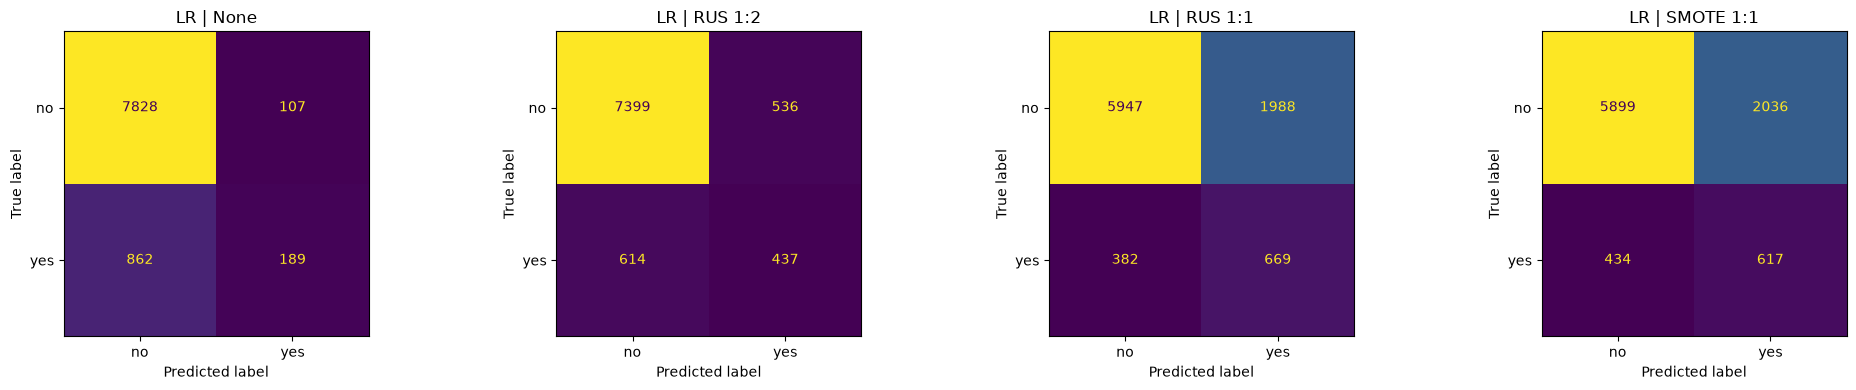

In [65]:
show_methods = ['처리 없음', 'RUS 1:2', 'RUS 1:1', 'SMOTE 1:1']   # 비교할 4가지
titles = ['None', 'RUS 1:2', 'RUS 1:1', 'SMOTE 1:1']

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, m, t in zip(axes, show_methods, titles):
    # 3-4에서 저장해 둔 확률을 꺼내서 0.5 기준으로 0/1 예측으로 바꿈
    #   → 모델을 다시 학습하지 않고 저장된 결과를 재사용
    pred = (imb_probas[('Logistic Regression', m)] >= 0.5).astype(int)

    # confusion_matrix: [[TN, FP], [FN, TP]] 형태의 2×2 표를 계산
    # ConfusionMatrixDisplay: 그 표를 그림으로 그려줌
    ConfusionMatrixDisplay(confusion_matrix(y_val, pred),
                           display_labels=['no', 'yes']).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(f'LR | {t}')

plt.tight_layout()
plt.show()

#### Confusion Matrix 해석
| LR 처리 방법 | TP (찾은 가입) | FP (헛걸음) | FN (놓친 가입) | 전화할 고객 수 (TP+FP) |
|---|---|---|---|---|
| 처리 없음 | 189 | 107 | 862 | 296 |
| RUS 1:2 (평균 순위 1위) | 437 | 536 | 614 | 973 |
| RUS 1:1 | 669 | 1,988 | 382 | 2,657 |
| SMOTE 1:1 | 616 | 2,034 | 435 | 2,650 |

- 처리 없음은 296명에게 전화해 189명이 가입(약 64%)하지만, 가입 고객의 82%를 놓침.
- RUS 1:2는 973명에게 전화해 437명이 가입(약 45%). 처리 없음보다 가입 고객을 2.3배 찾으면서 헛걸음은 536명 수준으로 관리됨.
- RUS 1:1은 2,657명에게 전화해 669명이 가입(약 25%). 가입 고객은 가장 많이 찾지만 헛걸음이 약 2,000명으로 급증함.
- SMOTE 1:1은 RUS 1:1과 전화할 고객 수가 비슷한데 찾은 가입 고객은 53명 적어(616 vs 669), 같은 비용으로 성과가 더 낮음.

## 3-8. 불균형 처리 종합
#### 개선 효과
- 임계값 0.5 기준에서 Recall이 크게 상승함 (LR 18.0% → 최대 63.7%). 불균형 처리를 하지 않으면 모델이 '가입' 예측을 지나치게 아끼는 문제를 해결함.
- 중간 강도의 처리(LR RUS 1:2)에서 네 지표의 평균 순위가 가장 좋음 (Accuracy 0.872, Precision 0.449, Recall 0.416, F1 0.432).

#### 부작용
- 처리 강도가 셀수록 Precision과 Accuracy가 급락하고 FP가 급증함 (LR RUS 1:1 기준 Precision 25.2%, Accuracy 73.6%, FP 1,988명).
- RUS는 미가입 고객 정보를 최대 87% 버리고, SMOTE는 실제 가입 고객의 최대 6.5배에 달하는 가짜 고객을 만듦. SMOTE는 같은 비율의 RUS보다 대체로 성과가 낮음.
- PR-AUC는 거의 변하지 않거나(RUS, Class Weight) 오히려 하락함(SMOTE). 불균형 처리는 고객을 줄 세우는 능력보다 '가입'으로 판단하는 기준을 바꾸는 효과가 큼.

#### 모델별 차이
- Logistic Regression은 처리 강도에 따라 네 지표가 고르게 반응해, 중간 강도에서 균형점을 찾을 수 있음.
- 기본 설정의 Decision Tree는 과적합으로 Class Weight가 거의 효과가 없고, Sampling은 Recall을 올리는 대신 Precision과 Accuracy를 크게 떨어뜨림.

#### 다음 단계에 반영할 점
- 4장에서 모든 모델에 같은 8가지 처리를 적용하고, 네 지표의 평균 순위로 최종 조합을 선택함.
- 중간 강도(1:3, 1:2)의 처리가 균형이 좋은지 다른 모델에서도 확인함.
- Logistic Regression과 KNN에는 4장에서 이상치 클리핑과 balance 로그 변환을 적용함.

In [43]:
imb_df.to_csv('imbalance_val.csv', index=False)
print('저장 완료: imbalance_val.csv')

저장 완료: imbalance_val.csv


# 4. 모델링
- 목적: 8개 모델 × 8가지 불균형 처리 방법을 같은 조건에서 비교하고, Stacking Ensemble까지 포함해 가장 좋은 조합을 찾음.
- 모델: Logistic Regression, Decision Tree, Random Forest, KNN, Gradient Boosting, XGBoost, LightGBM, AdaBoost, Stacking Ensemble
- 불균형 처리: 처리 없음, Class Weight, RUS(1:3, 1:2, 1:1), SMOTE(1:3, 1:2, 1:1) — 3장과 같은 방식
- 공통 조건
  - 하이퍼파라미터는 기본값 (튜닝은 성능 좋은 모델을 고른 뒤 진행)
  - 같은 Train으로 학습, 같은 Validation으로 평가 (Test는 최종 평가 전까지 사용하지 않음)
  - Sampling은 Train에만 적용하고 Validation은 실제 분포 유지
  - Logistic Regression과 KNN에는 이상치 클리핑 + balance 로그 변환을 Pipeline 첫 단계로 적용
- 평가 기준: Accuracy, Precision, Recall, F1 네 지표의 평균 순위 (전체 조합을 함께 순위 매김, PR-AUC는 참고용)

## 4-1. 모델링 라이브러리 불러오기
- XGBoost, LightGBM은 `pip install xgboost lightgbm`으로 먼저 설치해야 함.

In [57]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier, StackingClassifier)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

## 4-2. LR/KNN용 이상치 클리핑
- 대상: 값의 크기를 그대로 계산에 쓰는 Logistic Regression, 거리로 판단하는 KNN. 트리 계열은 값의 순서로만 분기하므로 적용하지 않음.
- 위치: 전처리 단계에서 데이터를 바꾸지 않고, 모델 Pipeline의 첫 단계로 넣음.
  - 클리핑 기준(상위 1%)은 fit 단계에서 Train으로만 계산되고 Validation·Test에는 같은 기준이 적용됨 (누수 방지)
  - Sampling보다 앞에 두어 원래 Train 분포에서 기준이 계산되도록 함
- 처리 내용
  - balance, campaign: 99번째 백분위수에서 클리핑
  - pdays: -1(이전 연락 없음)은 그대로 두고, 이전 연락 고객 기준 99번째 백분위수에서 클리핑
  - balance: 음수 잔고가 있어 부호를 유지하는 로그 변환 (sign(x) × log(1 + |x|))

In [66]:
class OutlierClipper(BaseEstimator, TransformerMixin):
    """
    극단값을 잘라주는 '파이프라인 단계'
    BaseEstimator, TransformerMixin을 상속하면 파이프라인에 넣을 수 있음
    (fit, transform 두 메서드만 만들면 됨)

    fit      : Train 데이터에서 자를 기준(상위 1% 값)을 '계산'해서 기억
    transform: 기억해 둔 기준으로 데이터를 '자름'
    → 파이프라인 안에 있으면 fit은 Train으로만 실행되므로 누수 없음
    """

    def __init__(self, cols=('balance', 'campaign', 'pdays'), q=0.99, log_balance=True):
        self.cols = cols                # 클리핑할 칼럼들
        self.q = q                      # 0.99 → 상위 1% 지점을 상한으로
        self.log_balance = log_balance  # balance 로그 변환 여부

    def fit(self, X, y=None):
        self.upper_ = {}                # 칼럼별 상한값을 저장할 딕셔너리
        for c in self.cols:
            # pdays는 -1(이전 연락 없음)이 82%라, 그대로 백분위수를 구하면 기준이 왜곡됨
            # → 이전 연락 고객(pdays != -1)만으로 상한을 계산
            s = X.loc[X['pdays'] != -1, 'pdays'] if c == 'pdays' else X[c]
            self.upper_[c] = s.quantile(self.q)
        # sklearn 규칙: 학습으로 얻은 값은 이름 끝에 '_'를 붙임 (upper_)
        return self

    def transform(self, X):
        X = X.copy()                    # 원본 데이터 보호
        for c, u in self.upper_.items():
            # clip(upper=u): u보다 큰 값은 u로 바꿈 (행은 삭제하지 않음)
            # pdays의 -1은 상한보다 작으므로 그대로 유지됨
            X[c] = X[c].clip(upper=u)

        if self.log_balance:
            # balance에는 음수 잔고가 있어 일반 log를 쓸 수 없음
            # sign(x) × log(1 + |x|) : 부호는 유지하면서 큰 값을 줄여줌
            #   예) 10000 → +9.21,  -2000 → -7.60,  0 → 0
            X['balance'] = np.sign(X['balance']) * np.log1p(X['balance'].abs())
        return X


# 확인용: Train 기준으로 계산된 상한값 출력
print('Train 기준 클리핑 상한:', {k: float(v) for k, v in OutlierClipper().fit(X_train).upper_.items()})

# ─────────────────────────────────────────────────────────────
# 클리핑 전후 비교 (LR, KNN × 적용 안 함/적용 = 4번)
# ─────────────────────────────────────────────────────────────
clip_rows = []
for name, model in [('Logistic Regression', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
                    ('KNN', KNeighborsClassifier(n_neighbors=5))]:
    for use_clip in [False, True]:
        # use_clip이 True면 [clip]을 맨 앞에 붙이고, False면 빈 리스트
        steps = ([('clip', OutlierClipper())] if use_clip else []) \
                + [('prep', make_preprocessor(True)), ('model', model)]
        res, _ = evaluate(f"{name} | {'클리핑+로그' if use_clip else '적용 안 함'}",
                          ImbPipeline(steps), X_train, y_train, X_val, y_val)
        clip_rows.append(res)

pd.DataFrame(clip_rows).set_index('모델')[RANK_METRICS + ['PR-AUC']]

Train 기준 클리핑 상한: {'balance': 12956.0, 'campaign': 16.0, 'pdays': 521.0}


,Accuracy,Precision,Recall,F1,PR-AUC
모델,,,,,
Logistic Regression | 적용 안 함,0.8922,0.6385,0.1798,0.2806,0.4034
Logistic Regression | 클리핑+로그,0.8928,0.6486,0.1827,0.2851,0.4040
KNN | 적용 안 함,0.8874,0.5512,0.1998,0.2933,0.2799
KNN | 클리핑+로그,0.8870,0.5433,0.2150,0.3081,0.2854


#### 클리핑 해석
- Train 기준 클리핑 상한은 balance 12,956, campaign 16회, pdays 521일임.
- Logistic Regression: 네 지표가 모두 소폭 개선되거나 비슷함 (Precision 0.639 → 0.649, F1 0.281 → 0.285).
- KNN: Recall 0.200 → 0.215, F1 0.293 → 0.308로 소폭 개선됨.
- 개선 폭이 작은 이유는 베이스라인 Permutation Importance에서 balance, campaign, pdays의 예측 기여도가 원래 작았기 때문임. 성능을 해치지 않으므로 이후 실험에서 두 모델에 적용함.

## 4-3. 모델 정의 및 Class Weight 적용 방식
| 모델 | Class Weight 적용 방식 | 스케일링·클리핑 |
|---|---|---|
| Logistic Regression | class_weight='balanced' | 적용 |
| KNN | 가중치 개념이 없어 Class Weight 실험 제외 (Sampling만 적용) | 적용 |
| Decision Tree | class_weight='balanced' | - |
| Random Forest | class_weight='balanced' | - |
| Gradient Boosting | 옵션이 없어 학습 시 sample_weight로 전달 | - |
| AdaBoost | 옵션이 없어 학습 시 sample_weight로 전달 | - |
| XGBoost | scale_pos_weight = 미가입 수 ÷ 가입 수 | - |
| LightGBM | class_weight='balanced' | - |

- Pipeline 순서: [클리핑(LR·KNN만)] → [Sampling] → [인코딩·스케일링] → [모델(+Class Weight)]

In [67]:
# XGBoost용 가중치: 미가입 수 ÷ 가입 수 = 23,779 ÷ 3,151 ≈ 7.55
#   가입 고객 가중치를 7.55배로 키우면 두 클래스의 전체 무게가 같아짐
#   (1이면 가중치 없음 = 처리 없음)
#   Train으로만 계산 → 누수 없음
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

# 스케일링 + 클리핑을 적용할 모델 (숫자 크기·거리에 민감한 모델)
SCALE_MODELS = {'Logistic Regression', 'KNN'}


def make_model(name, use_cw):
    """
    모델 이름을 받아 모델 객체를 만들어 주는 함수
    use_cw=True면 Class Weight를 켠 상태로 만듦
    """
    cw = 'balanced' if use_cw else None

    if name == 'Logistic Regression':
        return LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight=cw)
    if name == 'KNN':
        return KNeighborsClassifier(n_neighbors=5)          # 가중치 옵션 없음
    if name == 'Decision Tree':
        return DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight=cw)
    if name == 'Random Forest':
        return RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight=cw)
    if name == 'Gradient Boosting':
        return GradientBoostingClassifier(random_state=RANDOM_STATE)   # class_weight 옵션 없음 → fit 때 처리
    if name == 'AdaBoost':
        return AdaBoostClassifier(random_state=RANDOM_STATE)           # class_weight 옵션 없음 → fit 때 처리
    if name == 'XGBoost':
        return XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1,
                             # Class Weight 실험일 때만 7.55, 나머지는 1(가중치 없음)
                             # RUS/SMOTE 실험에서 가중치까지 주면 불균형 처리를 두 번 하는 셈이라 1로 둠
                             scale_pos_weight=scale_pos if use_cw else 1)
    if name == 'LightGBM':
        return LGBMClassifier(random_state=RANDOM_STATE, verbose=-1, class_weight=cw)


def build_model_pipeline(name, method):
    """
    3장의 build_pipeline을 8개 모델용으로 확장한 버전
    반환값: (파이프라인, fit_params)
      fit_params는 학습할 때 추가로 넘길 인자 (Gradient Boosting·AdaBoost의 Class Weight용)

    조립 결과 예시)
      LR + RUS 1:3          : [clip] → [sampler] → [prep(스케일링 O)] → [model]
      LightGBM + RUS 1:3    : [sampler] → [prep(스케일링 X)] → [model]
      LightGBM + CW         : [prep] → [model(class_weight='balanced')]
      GB + CW               : [prep] → [model]  + fit_params(sample_weight)
    """
    use_cw = (method == 'class_weight')
    steps = []

    # 1단계: 클리핑 (LR·KNN만)
    #   샘플링보다 앞에 두는 이유: 클리핑 기준(상위 1%)을 샘플링 전 '원래 Train 분포'에서 계산하기 위해
    if name in SCALE_MODELS:
        steps.append(('clip', OutlierClipper()))

    # 2단계: 샘플링 (RUS·SMOTE 실험일 때만)
    if method not in (None, 'class_weight'):
        steps.append(('sampler', method))

    # 3단계: 전처리, 4단계: 모델
    #   make_preprocessor(True/False): LR·KNN이면 스케일링 포함
    steps += [('prep', make_preprocessor(name in SCALE_MODELS)),
              ('model', make_model(name, use_cw))]

    # Gradient Boosting, AdaBoost의 Class Weight 처리
    #   이 두 모델은 class_weight 옵션이 없어서, 행마다 가중치를 계산해 fit할 때 넘김
    #   compute_sample_weight('balanced', y_train)
    #     → 가입 행에는 약 4.27, 미가입 행에는 약 0.57 (비율 7.5배 = class_weight='balanced'와 같은 효과)
    #   'model__sample_weight' : 파이프라인의 'model' 단계에 sample_weight로 전달하라는 뜻
    #                             (형식: 단계이름__인자이름)
    fit_params = None
    if use_cw and name in ('Gradient Boosting', 'AdaBoost'):
        fit_params = {'model__sample_weight': compute_sample_weight('balanced', y_train)}

    return ImbPipeline(steps), fit_params


def evaluate_model(name, pipe, fit_params=None, threshold=0.5):
    """
    2장의 evaluate와 같은 역할 + fit_params를 받을 수 있도록 확장
    학습 → Validation 예측 → 지표 계산
    """
    start = time.time()
    # **(fit_params or {})
    #   fit_params가 있으면 그 내용을 키워드 인자로 풀어서 전달
    #     예) pipe.fit(X_train, y_train, model__sample_weight=가중치)
    #   None이면 빈 딕셔너리로 바꿔서 아무것도 전달하지 않음
    pipe.fit(X_train, y_train, **(fit_params or {}))
    train_time = time.time() - start

    # predict_proba는 [미가입 확률, 가입 확률] 두 칼럼을 돌려줌 → [:, 1]로 가입 확률만 사용
    proba = pipe.predict_proba(X_val)[:, 1]

    # 임계값 0.5 이상이면 가입(1), 미만이면 미가입(0)
    pred = (proba >= threshold).astype(int)

    # confusion_matrix(...).ravel(): 2×2 표를 [TN, FP, FN, TP] 순서로 펼침
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()

    return {
        '모델': name,
        'Accuracy':  round(accuracy_score(y_val, pred), 4),
        'Precision': round(precision_score(y_val, pred, zero_division=0), 4),   # zero_division=0: '가입' 예측이 0건일 때 에러 대신 0
        'Recall':    round(recall_score(y_val, pred, zero_division=0), 4),
        'F1':        round(f1_score(y_val, pred, zero_division=0), 4),
        'PR-AUC':    round(average_precision_score(y_val, proba), 4),         # 참고용
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
        '학습 시간(초)': round(train_time, 2),
    }, proba

## 4-4. 실험 실행
- 8개 모델 × 8가지 방법 = 63개 조합 (KNN의 Class Weight 제외)
- Random Forest와 SMOTE 조합이 가장 오래 걸려 전체 실행에 수 분이 소요됨.

In [68]:
model_names = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest',
               'Gradient Boosting', 'AdaBoost', 'XGBoost', 'LightGBM']

model_rows, model_probas = [], {}
total_start = time.time()

# 3장과 같은 2중 반복문 구조: 8 × 8 = 64번, KNN + Class Weight 1개 제외 → 63번
for name in model_names:
    for method_name, method in methods.items():        # methods는 3-3에서 만든 도구 딕셔너리를 그대로 재사용

        # KNN은 가중치 개념이 없어서 Class Weight 실험은 건너뜀
        if name == 'KNN' and method == 'class_weight':
            continue

        # (1) 파이프라인 조립 (아직 학습 X)
        pipe, fit_params = build_model_pipeline(name, method)

        # (2) 학습·예측·지표 계산
        #   샘플링은 바로 여기, evaluate_model 안의 pipe.fit() 때 실행됨
        #   → 그래서 "언더샘플링 셀"이 따로 필요 없음
        res, proba = evaluate_model(f'{name} | {method_name}', pipe, fit_params)

        # (3) 기록
        res['모델명'] = name
        res['처리 방법'] = method_name
        model_rows.append(res)
        model_probas[(name, method_name)] = proba

    # 모델 하나(8가지 처리)가 끝날 때마다 누적 시간 출력
    # {name:20s}: 이름을 20칸 너비로 맞춰 출력 (줄 맞춤용)
    print(f'{name:20s} 완료 (누적 {time.time() - total_start:.0f}초)')

model_df = pd.DataFrame(model_rows)

Logistic Regression  완료 (누적 8초)
KNN                  완료 (누적 58초)
Decision Tree        완료 (누적 78초)
Random Forest        완료 (누적 97초)
Gradient Boosting    완료 (누적 136초)
AdaBoost             완료 (누적 153초)
XGBoost              완료 (누적 161초)
LightGBM             완료 (누적 169초)


#### 실행 결과 해석
- 63개 조합을 모두 같은 Train·Validation·지표로 평가함.
- 학습 시간: Gradient Boosting이 가장 오래 걸림. RUS는 데이터가 줄어 빨라지고, SMOTE는 데이터가 늘어 느려짐. 실행 환경에 따라 시간은 달라질 수 있음.

## 4-5. 처리 없음 기준 모델 비교

In [69]:
# 처리 없음인 행만 골라서 모델끼리 비교
base_cmp = (model_df[model_df['처리 방법'] == '처리 없음']
            .set_index('모델명')[RANK_METRICS + ['PR-AUC', '학습 시간(초)']]
            .sort_values('F1', ascending=False))
display(base_cmp)

,Accuracy,Precision,Recall,F1,PR-AUC,학습 시간(초)
모델명,,,,,,
XGBoost,0.8933,0.5939,0.2769,0.3777,0.4267,0.22
LightGBM,0.8941,0.6112,0.2588,0.3636,0.4395,0.20
Random Forest,0.8922,0.5976,0.2388,0.3413,0.4108,1.43
Decision Tree,0.8310,0.3000,0.3340,0.3161,0.1781,1.79
Gradient Boosting,0.8932,0.6304,0.2093,0.3143,0.4279,3.94
KNN,0.8870,0.5433,0.2150,0.3081,0.2854,0.15
Logistic Regression,0.8928,0.6486,0.1827,0.2851,0.4040,0.16
AdaBoost,0.8915,0.6357,0.1694,0.2675,0.3772,1.32


#### 처리 없음 기준 해석
| 모델 | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| XGBoost | 0.893 | 0.594 | 0.277 | 0.378 |
| LightGBM | 0.894 | 0.611 | 0.259 | 0.364 |
| Random Forest | 0.892 | 0.598 | 0.239 | 0.341 |
| Decision Tree | 0.831 | 0.300 | 0.334 | 0.316 |
| Gradient Boosting | 0.893 | 0.630 | 0.209 | 0.314 |
| KNN | 0.887 | 0.543 | 0.215 | 0.308 |
| Logistic Regression | 0.893 | 0.649 | 0.183 | 0.285 |
| AdaBoost | 0.892 | 0.636 | 0.169 | 0.268 |

- Decision Tree를 제외하면 Accuracy가 모두 0.887~0.894로 Dummy(0.883)와 거의 같아, 처리 없음에서는 Accuracy로 모델을 구분할 수 없음.
- 모든 모델이 Precision은 54~65%로 높지만 Recall은 17~28%로 낮음. 불균형 때문에 '가입' 예측을 매우 조심스럽게 하는 상태임.
- 처리 없음에서는 Recall이 비교적 높은 XGBoost(F1 0.378)와 LightGBM(0.364)이 가장 균형이 좋음.

## 4-6. 지표별 비교

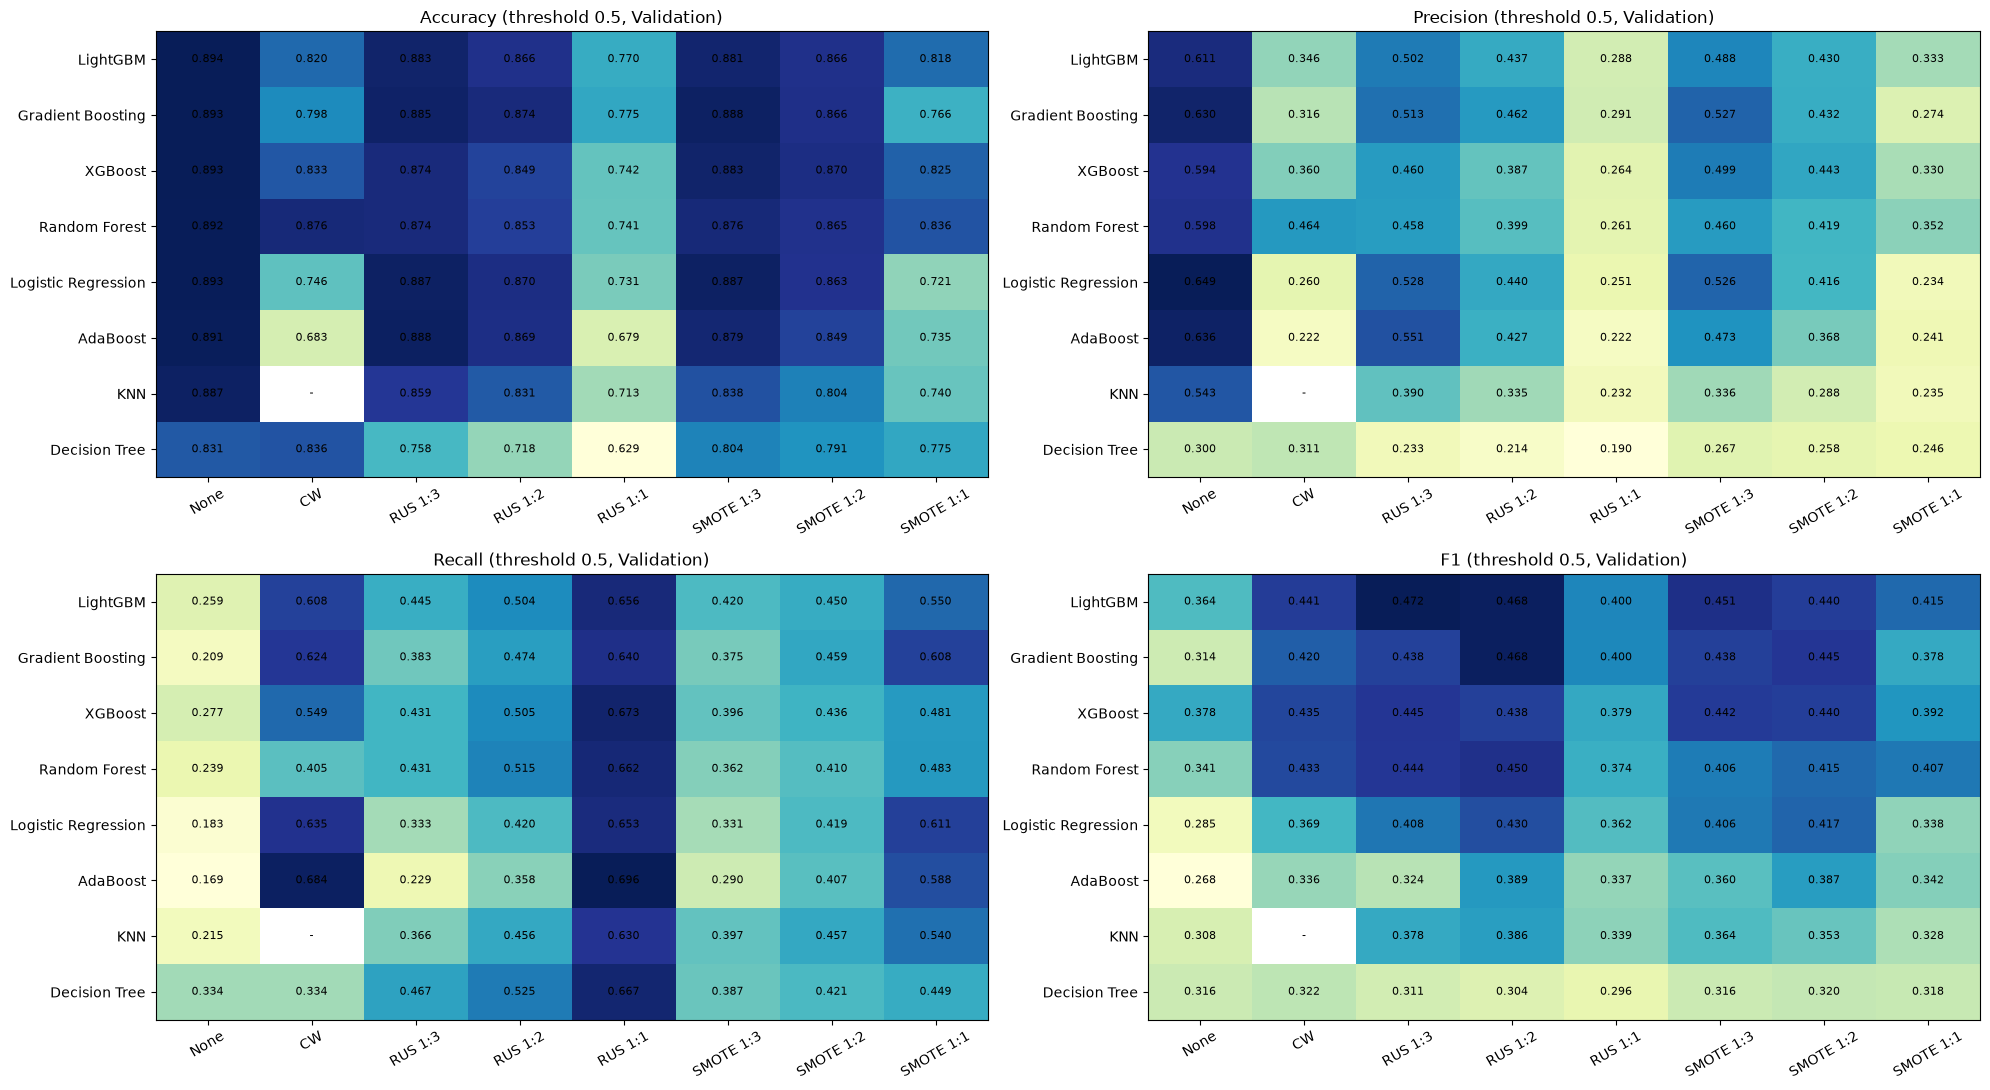

지표별 1등 조합
  Accuracy : LightGBM | 처리 없음 (0.8941)
  Precision: Logistic Regression | 처리 없음 (0.6486)
  Recall   : AdaBoost | RUS 1:1 (0.6955)
  F1       : LightGBM | RUS 1:3 (0.4718)
Accuracy가 Dummy(0.883)보다 낮은 조합: 50 / 63


In [71]:
order = list(methods.keys())
order_en = ['None', 'CW', 'RUS 1:3', 'RUS 1:2', 'RUS 1:1', 'SMOTE 1:3', 'SMOTE 1:2', 'SMOTE 1:1']
model_order = ['LightGBM', 'Gradient Boosting', 'XGBoost', 'Random Forest',
               'Logistic Regression', 'AdaBoost', 'KNN', 'Decision Tree']

def heatmap(df, metric, title, ax, cmap='YlGnBu'):
    """
    모델(행) × 처리 방법(열) 표를 색깔 칸으로 그리는 함수
    """
    # pivot: 긴 표(한 줄 = 한 조합)를 '모델 × 처리 방법' 격자 표로 바꿈
    pv = df.pivot(index='모델명', columns='처리 방법', values=metric).loc[model_order, order]

    im = ax.imshow(pv.values, cmap=cmap, aspect='auto')   # 값에 따라 색칠
    ax.set_xticks(range(len(order_en))); ax.set_xticklabels(order_en, rotation=30)
    ax.set_yticks(range(len(model_order))); ax.set_yticklabels(model_order)

    # 칸마다 숫자 써넣기 (KNN의 Class Weight처럼 값이 없는 칸은 '-')
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]):
            v = pv.values[i, j]
            ax.text(j, i, '-' if np.isnan(v) else f'{v:.3f}', ha='center', va='center', fontsize=8)
    ax.set_title(title)
    return pv

# 2×2 칸에 네 지표 히트맵을 하나씩
fig, axes = plt.subplots(2, 2, figsize=(20, 11))
pivots = {}
for ax, metric in zip(axes.ravel(), RANK_METRICS):    # axes.ravel(): 2×2 칸을 한 줄로 펼침
    pivots[metric] = heatmap(model_df, metric, f'{metric} (threshold 0.5, Validation)', ax)
plt.tight_layout()
plt.show()

# 지표별 1등 조합 확인
print('지표별 1등 조합')
for metric in RANK_METRICS:
    top = model_df.sort_values(metric, ascending=False).iloc[0]    # 내림차순 정렬 후 첫 행
    print(f'  {metric:9s}: {top["모델"]} ({top[metric]:.4f})')

print('Accuracy가 Dummy(0.883)보다 낮은 조합:', (model_df['Accuracy'] < 0.883).sum(), '/', len(model_df))

#### 지표별 해석
- Accuracy: 모든 모델에서 처리 없음이 가장 높고(약 0.89), RUS 1:1에서 0.63~0.78까지 떨어짐. 63개 조합 중 49개가 Dummy(0.883)보다 낮음. 가입 고객을 더 찾을수록 Accuracy는 떨어지는 구조임.
- Precision: 처리 없음에서 가장 높고(LR 0.649 최고), 처리 강도가 셀수록 낮아짐 (RUS 1:1에서 0.19~0.29).
- Recall: 처리 강도가 셀수록 높아짐. RUS 1:1에서 0.63~0.70 (AdaBoost 0.696 최고, XGBoost 0.673, DT 0.667).
- F1: 중간 강도(RUS 1:3, 1:2)에서 가장 높음. LightGBM RUS 1:3(0.472), LightGBM RUS 1:2(0.468), Gradient Boosting RUS 1:2(0.468) 순.
- 지표별 1등이 모두 다름: Accuracy와 Precision은 '조심스러운' 조합(처리 없음), Recall은 '과감한' 조합(RUS 1:1), F1은 '중간' 조합에서 1등이 나옴. 지표들이 서로 반대로 움직이기 때문에 한 지표만 보면 판단이 한쪽으로 치우침. 그래서 네 지표의 평균 순위로 선택함.

## 4-7. Stacking Ensemble
#### 구성 모델 선정
- Stacking은 서로 다르게 판단하는 모델을 섞을 때 효과가 큼. 처리 없음 기준 모델 간 예측 확률의 순위 상관을 확인해 구성 모델을 고름.

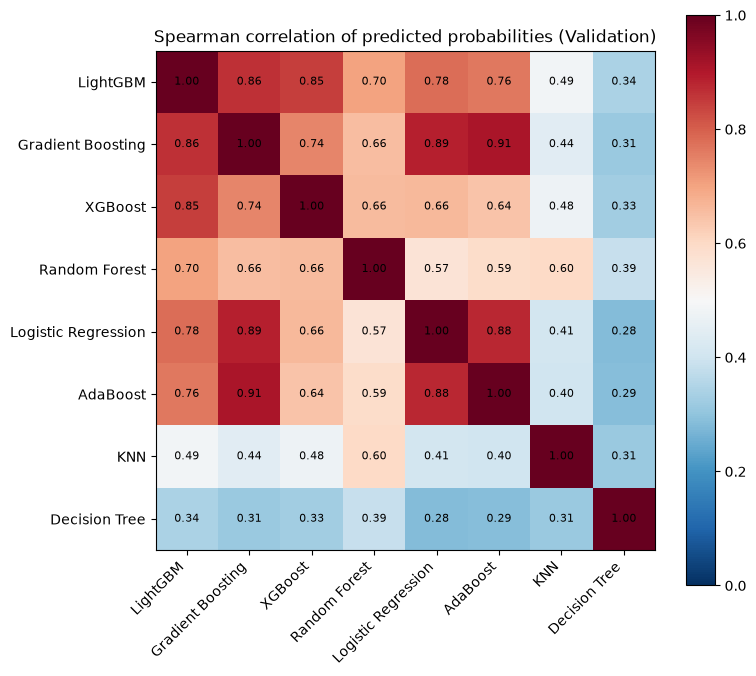

In [74]:
# 처리 없음 기준 모델별 예측 확률을 칼럼으로 모음 (4-4에서 저장한 것 재사용)
proba_df = pd.DataFrame({n: model_probas[(n, '처리 없음')] for n in model_order})

# 스피어만 상관: 두 모델이 고객을 '비슷한 순서'로 줄 세우는지 (1에 가까울수록 비슷)
#   → 비슷하게 판단하는 모델끼리는 섞어도 효과가 작음
corr = proba_df.corr(method='spearman')

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=0, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('Spearman correlation of predicted probabilities (Validation)')
plt.colorbar(im)
plt.tight_layout()
plt.show()

#### 예측 상관 해석 및 구성 결정
- 부스팅 계열끼리 예측이 매우 비슷함: Gradient Boosting–AdaBoost 0.91, LightGBM–Gradient Boosting 0.86, LightGBM–XGBoost 0.85. 부스팅을 여러 개 넣어도 비슷한 판단이 겹칠 가능성이 큼.
- Random Forest는 LightGBM과 0.70, Logistic Regression과 0.57로 다르게 판단하는 편이라 다양성을 더해줌.
- KNN과 Decision Tree는 다른 모델과 상관이 낮지만 개별 성능이 낮아 기여하기 어려움.
- 구성 A: Logistic Regression(선형) + Random Forest(배깅) + LightGBM(부스팅 대표). 계열별 대표 하나씩.
- 구성 B (비교용): 구성 A + XGBoost + Gradient Boosting. 상관이 높은 부스팅을 더 넣었을 때 효과가 있는지 확인.
- 불균형 처리: 처리 없음과, 4-6에서 F1이 가장 좋았던 RUS 1:3을 구성 A에 적용해 비교함. RUS는 Stacking 전체 앞에 두어 Train에만 적용함.
- 최종 판단은 Logistic Regression이 하며, cv=5로 구성 모델의 예측을 교차검증으로 만들어 누수를 막음.

In [75]:
def make_stacking(members):
    """
    Stacking: 여러 모델(구성 모델)의 예측 확률을 다시 입력으로 받아
              최종 모델(LR)이 마지막 판단을 내리는 방식
    """
    # 구성 모델마다 4-3의 파이프라인을 그대로 사용 (처리 없음 버전)
    #   → LR은 [clip → prep(스케일링) → model], RF·LightGBM은 [prep → model]
    #   build_model_pipeline은 (파이프라인, fit_params)를 돌려주므로 [0]으로 파이프라인만 꺼냄
    estimators = [(name, build_model_pipeline(name, None)[0]) for name in members]

    return StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),   # 최종 판단 모델

        # cv=5: 구성 모델의 예측을 '교차검증'으로 만듦
        #   Train을 5등분 → 4개로 학습, 나머지 1개를 예측 → 5번 반복
        #   → Train의 모든 고객에 대해 "그 고객을 보지 않은 모델의 예측"이 생김
        #   이걸로 최종 LR을 학습해야, 구성 모델이 이미 외운 답으로 학습하는 누수를 막을 수 있음
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),

        stack_method='predict_proba',   # 구성 모델의 '확률'을 최종 모델의 입력으로 사용
        n_jobs=-1)


members_A = ['Logistic Regression', 'Random Forest', 'LightGBM']   # 계열별 대표 하나씩
members_B = members_A + ['XGBoost', 'Gradient Boosting']           # 비슷한 부스팅을 더 넣은 비교용

# (이름, 처리 방법, 구성 모델, 샘플러)
stack_configs = [
    ('Stacking A (LR+RF+LGBM)', '처리 없음', members_A, None),
    ('Stacking B (A+XGB+GB)',   '처리 없음', members_B, None),
    ('Stacking A (LR+RF+LGBM)', 'RUS 1:3',  members_A, RandomUnderSampler(sampling_strategy=1/3, random_state=RANDOM_STATE)),
]

stack_rows = []
for label, method_name, members, sampler in stack_configs:
    stk = make_stacking(members)

    # 샘플러가 있으면 Stacking '전체' 앞에 붙임
    #   [sampler] → [stack]
    #   → RUS로 줄어든 Train 하나로 구성 모델과 최종 모델이 모두 학습됨
    if sampler is not None:
        pipe = ImbPipeline([('sampler', sampler), ('stack', stk)])
    else:
        pipe = ImbPipeline([('stack', stk)])

    res, proba = evaluate_model(f'{label} | {method_name}', pipe)
    res['모델명'] = label
    res['처리 방법'] = method_name
    stack_rows.append(res)
    model_probas[(label, method_name)] = proba

    # 최종 LR이 각 구성 모델에 준 가중치 (클수록 최종 판단에 많이 반영됨)
    weights = pipe.named_steps['stack'].final_estimator_.coef_[0].round(3)
    print(f'{label} | {method_name} 최종 모델 가중치:', dict(zip(members, weights)))

stack_df = pd.DataFrame(stack_rows)
stack_df.set_index('모델')[RANK_METRICS + ['PR-AUC', '학습 시간(초)']]

Stacking A (LR+RF+LGBM) | 처리 없음 최종 모델 가중치: {'Logistic Regression': np.float64(0.594), 'Random Forest': np.float64(2.166), 'LightGBM': np.float64(3.565)}
Stacking B (A+XGB+GB) | 처리 없음 최종 모델 가중치: {'Logistic Regression': np.float64(0.245), 'Random Forest': np.float64(2.014), 'LightGBM': np.float64(3.189), 'XGBoost': np.float64(0.121), 'Gradient Boosting': np.float64(0.73)}
Stacking A (LR+RF+LGBM) | RUS 1:3 최종 모델 가중치: {'Logistic Regression': np.float64(0.889), 'Random Forest': np.float64(1.506), 'LightGBM': np.float64(2.976)}


,Accuracy,Precision,Recall,F1,PR-AUC,학습 시간(초)
모델,,,,,,
Stacking A (LR+RF+LGBM) | 처리 없음,0.8944,0.6209,0.2493,0.3557,0.4461,26.66
Stacking B (A+XGB+GB) | 처리 없음,0.8948,0.6262,0.2502,0.3576,0.4467,26.04
Stacking A (LR+RF+LGBM) | RUS 1:3,0.8827,0.4984,0.4415,0.4682,0.4331,12.07


#### Stacking 해석
| 조합 | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Stacking A, 처리 없음 | 0.894 | 0.621 | 0.249 | 0.356 |
| Stacking B, 처리 없음 | 0.895 | 0.626 | 0.250 | 0.358 |
| Stacking A, RUS 1:3 | 0.883 | 0.498 | 0.442 | 0.468 |

- 처리 없음에서는 Stacking도 다른 단일 모델처럼 Precision은 높고 Recall은 25% 수준으로 낮음.
- RUS 1:3을 적용하면 Recall이 0.249 → 0.442로 오르고 Precision은 0.498로 유지되어 F1이 0.468까지 올라감.
- 구성 B는 구성 A와 거의 같은 결과이며, 추가한 XGBoost(가중치 0.12)와 Gradient Boosting(0.73)의 기여가 작음. 예측이 비슷한 부스팅을 더 넣어도 얻는 것이 거의 없음을 확인함.
- 최종 모델 가중치는 LightGBM이 가장 크고(약 3), 다음이 Random Forest(1.5~2.2)로, 두 모델이 판단의 대부분을 담당함.

## 4-8. 평균 순위로 최종 비교

In [76]:
# 개별 모델 63개 + Stacking 3개 = 66개를 하나의 표로 합친 뒤 '함께' 순위 매김
#   ⚠️ 따로따로 순위를 매기면 비교 대상이 달라서 순위끼리 비교할 수 없음
all_df = add_avg_rank(pd.concat([model_df, stack_df], ignore_index=True))
print('전체 조합 수:', len(all_df))

# 상위 10개
all_df.sort_values('평균 순위').set_index('모델')[RANK_METRICS + ['평균 순위', 'PR-AUC', 'TP', 'FP']].head(10)

전체 조합 수: 66


,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,TP,FP
모델,,,,,,,,
LightGBM | RUS 1:3,0.8834,0.5016,0.4453,0.4718,15.75,0.4267,468,465
Stacking A (LR+RF+LGBM) | RUS 1:3,0.8827,0.4984,0.4415,0.4682,17.38,0.4331,464,467
Gradient Boosting | RUS 1:2,0.8740,0.4624,0.4738,0.4680,18.25,0.4187,498,579
LightGBM | SMOTE 1:3,0.8807,0.4884,0.4196,0.4514,19.88,0.4180,441,462
LightGBM | RUS 1:2,0.8660,0.4369,0.5043,0.4682,20.25,0.4224,530,683
Gradient Boosting | SMOTE 1:3,0.8876,0.5274,0.3749,0.4383,21.12,0.4153,394,353
XGBoost | SMOTE 1:3,0.8829,0.4994,0.3958,0.4416,21.75,0.4075,416,417
XGBoost | RUS 1:3,0.8742,0.4599,0.4310,0.4450,22.12,0.4065,453,532
Gradient Boosting | SMOTE 1:2,0.8662,0.4323,0.4586,0.4451,22.50,0.3987,482,633


In [77]:
# 모델별로 가장 좋은 처리 방법 하나씩
#   평균 순위로 정렬 → 모델명별로 첫 번째 행만 남김 (groupby().head(1))
best_per_model = (all_df.sort_values('평균 순위')
                  .groupby('모델명').head(1)
                  .set_index('모델명')[['처리 방법'] + RANK_METRICS + ['평균 순위', 'PR-AUC', '학습 시간(초)']])
best_per_model

,처리 방법,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,학습 시간(초)
모델명,,,,,,,,
LightGBM,RUS 1:3,0.8834,0.5016,0.4453,0.4718,15.75,0.4267,0.15
Stacking A (LR+RF+LGBM),RUS 1:3,0.8827,0.4984,0.4415,0.4682,17.38,0.4331,12.07
Gradient Boosting,RUS 1:2,0.8740,0.4624,0.4738,0.4680,18.25,0.4187,1.61
XGBoost,SMOTE 1:3,0.8829,0.4994,0.3958,0.4416,21.75,0.4075,1.79
Random Forest,RUS 1:3,0.8738,0.4580,0.4310,0.4441,23.12,0.3958,0.61
Logistic Regression,RUS 1:3,0.8872,0.5279,0.3330,0.4084,25.00,0.4023,0.11
Stacking B (A+XGB+GB),처리 없음,0.8948,0.6262,0.2502,0.3576,27.00,0.4467,26.04
AdaBoost,RUS 1:3,0.8880,0.5515,0.2293,0.3239,33.50,0.3688,0.61
KNN,RUS 1:2,0.8307,0.3354,0.4558,0.3864,36.25,0.2996,0.05


#### 평균 순위 해석
| 순위 | 조합 | 평균 순위 | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| 1 | LightGBM, RUS 1:3 | 16.00 | 0.883 | 0.502 | 0.445 | 0.472 |
| 2 | Stacking A, RUS 1:3 | 17.25 | 0.883 | 0.498 | 0.442 | 0.468 |
| 3 | Gradient Boosting, RUS 1:2 | 18.50 | 0.874 | 0.462 | 0.474 | 0.468 |
| 4 | LightGBM, RUS 1:2 | 20.12 | 0.866 | 0.437 | 0.504 | 0.468 |
| 5 | Gradient Boosting, RUS 1:3 | 21.25 | 0.885 | 0.513 | 0.383 | 0.438 |

- 전체 66개 조합 중 LightGBM + RUS 1:3이 평균 순위 1위임. Accuracy는 Dummy 수준(0.883)을 유지하면서, Precision 50%와 Recall 45%로 두 지표가 균형을 이룸.
- Stacking A + RUS 1:3이 2위로 LightGBM과 거의 같은 성능이지만, 학습 시간이 훨씬 김.
- 상위권은 모두 부스팅 계열 + 중간 강도의 RUS(1:3, 1:2)임.
- 모델별 최고 조합: LightGBM(RUS 1:3, 16.00) > Stacking A(RUS 1:3, 17.25) > Gradient Boosting(RUS 1:2, 18.50) > XGBoost(RUS 1:3, 21.75) > Random Forest(RUS 1:3, 22.75) > Logistic Regression(RUS 1:3, 25.50) > AdaBoost(RUS 1:3, 34.00) > KNN(RUS 1:2, 36.00) > Decision Tree(SMOTE 1:1, 46.00)
- 대부분 모델에서 RUS 1:3이 가장 좋은 처리 방법으로 나타남.

## 4-9. 모델별로 불균형 처리 효과가 다른 이유

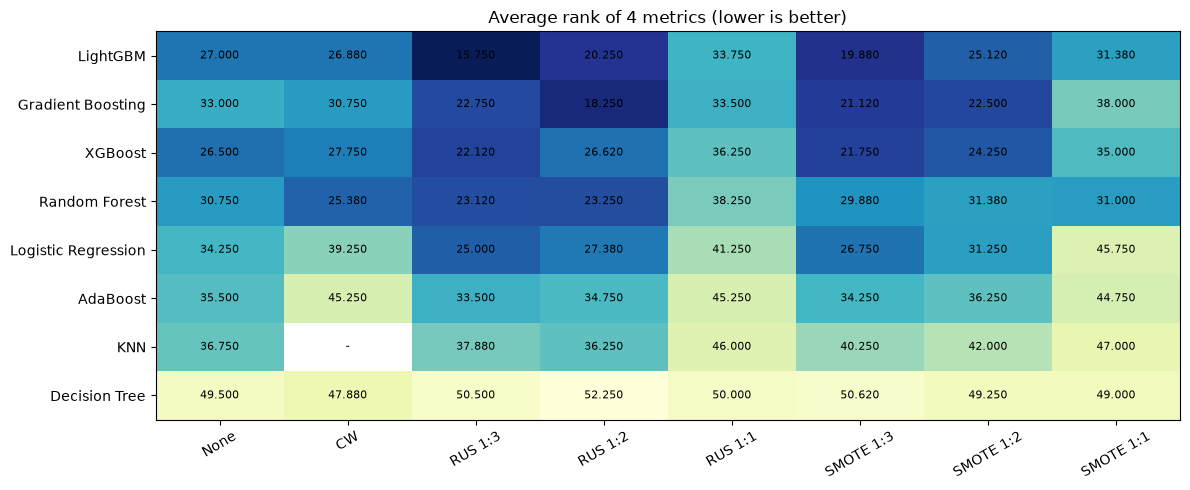

처리 방법별 평균 순위 (8개 모델 평균)


처리 방법
처리 없음           34.2
Class Weight    34.7
RUS 1:3         28.8
RUS 1:2         29.9
RUS 1:1         40.5
SMOTE 1:3       30.6
SMOTE 1:2       32.8
SMOTE 1:1       40.2
Name: 평균 순위, dtype: float64

In [78]:
# Stacking을 뺀 개별 모델 63개만 (Stacking은 처리 방법이 일부뿐이라 격자 표를 채울 수 없음)
base_only = all_df[all_df['모델명'].isin(model_names)]

# 평균 순위 히트맵 (작을수록 좋으므로 색을 뒤집은 cmap='YlGnBu_r' 사용)
fig, ax = plt.subplots(figsize=(12, 5))
rank_pv = heatmap(base_only, '평균 순위', 'Average rank of 4 metrics (lower is better)', ax, cmap='YlGnBu_r')
plt.tight_layout()
plt.show()

# 처리 방법별로 8개 모델의 평균 순위를 다시 평균 → 어떤 처리가 전반적으로 좋은지
print('처리 방법별 평균 순위 (8개 모델 평균)')
base_only.groupby('처리 방법')['평균 순위'].mean().loc[order].round(1)

#### 모델별 차이 해석
- 처리 방법별 평균: RUS 1:3(28.6) < RUS 1:2(29.5) < SMOTE 1:3(31.5) < SMOTE 1:2(32.9) < 처리 없음(33.7) < Class Weight(35.9) < SMOTE 1:1(39.6) < RUS 1:1(40.2). 중간 강도의 처리가 가장 좋고, 1:1처럼 강한 처리는 처리 없음보다도 나쁨.
- 부스팅 계열 (LightGBM, Gradient Boosting, XGBoost)
  - 중간 강도 RUS에서 평균 순위가 크게 좋아짐 (LightGBM 26.2 → 16.0, Gradient Boosting 32.2 → 18.5). 부스팅은 원래 확률을 촘촘하게 잘 줄 세우기 때문에, 약간의 처리로 '가입' 기준만 조금 낮춰주면 Precision을 크게 잃지 않고 Recall을 올릴 수 있음.
- 트리 계열 (Random Forest, Decision Tree)
  - Class Weight가 거의 효과가 없음 (RF Recall 0.239 → 0.206, DT 0.334 → 0.329). 깊이 제한 없이 자란 트리는 잎마다 한 클래스만 남아 가중치가 판단에 영향을 주지 못함.
  - Random Forest는 Sampling(RUS 1:3)으로는 개선됨(30.2 → 22.8). 데이터 자체가 바뀌면 트리 구조가 달라지기 때문임. Decision Tree는 과적합으로 어떤 처리에서도 하위권임.
- Logistic Regression
  - RUS 1:3(25.5)과 SMOTE 1:3(25.6)에서 가장 좋음. Class Weight(39.0)는 처리 강도가 RUS 1:1과 비슷하게 세서 Precision이 크게 떨어짐.
- KNN
  - RUS 1:2(36.0)에서 가장 좋음. 이웃 5명 중 대부분이 미가입 고객이라, 미가입을 줄이면 이웃 구성이 가입 여부를 더 잘 반영하게 됨. 반면 SMOTE는 가짜 고객이 이웃으로 섞여 나빠짐.
- AdaBoost
  - Class Weight에서 Recall은 크게 오르지만(0.169 → 0.684) Precision이 0.222로 떨어져 평균 순위가 나빠짐. 얕은 트리 여러 개로 판단해 확률이 거칠어, 가중치가 판단 기준을 한꺼번에 크게 옮기기 때문임.
- 정리: 불균형 처리의 적정 강도는 모델마다 다르지만, 대부분 모델에서 가입 : 미가입 = 1:3 정도의 중간 강도가 네 지표의 균형이 가장 좋음.

## 4-10. 최종 후보 상세 비교

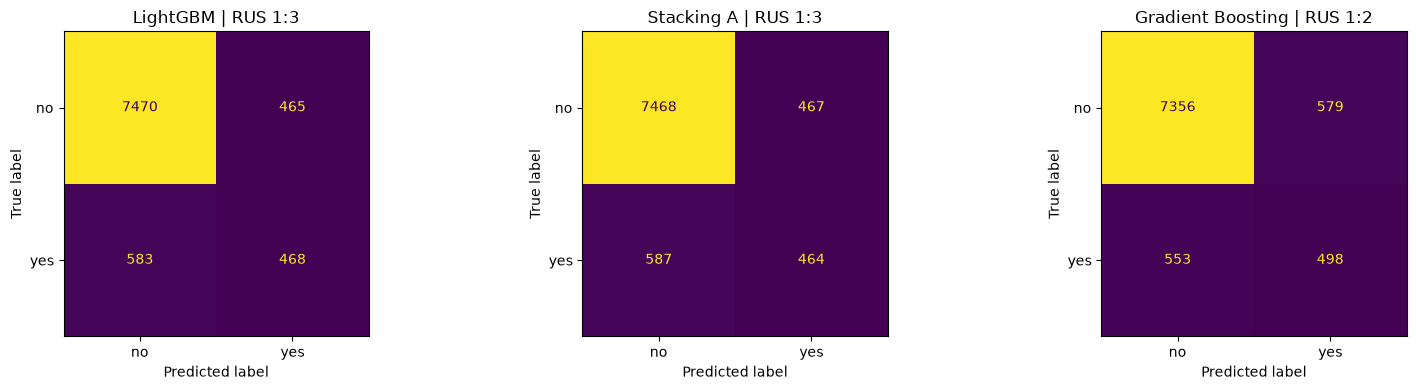

,,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,TP,FP,FN,학습 시간(초)
모델명,처리 방법,,,,,,,,,,
LightGBM,RUS 1:3,0.8834,0.5016,0.4453,0.4718,15.75,0.4267,468,465,583,0.15
Stacking A (LR+RF+LGBM),RUS 1:3,0.8827,0.4984,0.4415,0.4682,17.38,0.4331,464,467,587,12.07
Gradient Boosting,RUS 1:2,0.8740,0.4624,0.4738,0.4680,18.25,0.4187,498,579,553,1.61


In [79]:
finalists = [('LightGBM', 'RUS 1:3'),
             ('Stacking A (LR+RF+LGBM)', 'RUS 1:3'),
             ('Gradient Boosting', 'RUS 1:2')]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, m) in zip(axes, finalists):
    # 저장해 둔 확률로 Confusion Matrix 그리기 (재학습 없음)
    pred = (model_probas[(name, m)] >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_val, pred),
                           display_labels=['no', 'yes']).plot(ax=ax, colorbar=False, values_format='d')
    # 제목이 길어지지 않도록 'Stacking A (LR+RF+LGBM)' → 'Stacking A'
    ax.set_title(f"{name.split(' (')[0]} | {m}")
plt.tight_layout()
plt.show()

# (모델명, 처리 방법) 두 칼럼을 인덱스로 만들어 finalists 목록으로 바로 찾아옴
final_cmp = all_df.set_index(['모델명', '처리 방법']).loc[finalists][
    RANK_METRICS + ['평균 순위', 'PR-AUC', 'TP', 'FP', 'FN', '학습 시간(초)']]
final_cmp

#### 최종 후보 해석
| 후보 | TP (찾은 가입) | FP (헛걸음) | FN (놓친 가입) | 전화할 고객 수 |
|---|---|---|---|---|
| LightGBM, RUS 1:3 | 468 | 465 | 583 | 933 |
| Stacking A, RUS 1:3 | 464 | 467 | 587 | 931 |
| Gradient Boosting, RUS 1:2 | 498 | 579 | 553 | 1,077 |

- LightGBM과 Stacking A는 거의 같은 결과로, 약 930명에게 전화해 약 465명이 가입함(2명 중 1명). 가입 고객의 약 44%를 찾음.
- Gradient Boosting RUS 1:2는 약 1,080명에게 전화해 498명이 가입함. LightGBM보다 가입 고객을 30명 더 찾지만 헛걸음도 114명 더 많음.
- 처리 없는 베이스라인 LR(전화 296명, 가입 189명)과 비교하면, 가입 고객을 약 2.5배 더 찾으면서 Precision은 약 50%로 유지됨.
- LightGBM은 학습 시간이 1초 미만으로 Stacking보다 훨씬 빨라, 성능이 비슷하다면 운영 측면에서 유리함.

## 4-11. 모델링 종합 및 다음 단계
#### 종합
- 네 지표(Accuracy, Precision, Recall, F1)의 평균 순위 기준으로 LightGBM + RUS 1:3이 66개 조합 중 1위이며, Stacking A + RUS 1:3, Gradient Boosting + RUS 1:2가 뒤를 이음.
- 지표별 1등은 모두 다름: Accuracy·Precision은 처리 없음, Recall은 RUS 1:1, F1은 중간 강도 처리에서 1등이 나와, 한 지표만으로는 판단이 한쪽으로 치우침.
- 불균형 처리의 개선 효과: 모든 모델에서 Recall이 2~4배 증가함 (처리 없음 17~33% → RUS 1:1 63~70%).
- 불균형 처리의 부작용: 강도가 셀수록 Precision과 Accuracy가 급락하고 FP가 급증함. 1:1 처리는 평균 순위가 처리 없음보다도 나쁨.
- 모델별 차이: 부스팅 계열은 중간 강도 처리로 크게 좋아지고, 끝까지 자란 트리는 Class Weight가 효과가 없으며, KNN은 RUS에서 좋아지고 SMOTE에서 나빠짐.

#### 자세히 분석할 후보
- LightGBM + RUS 1:3: 평균 순위 1위, 학습 1초 미만으로 빠름
- Gradient Boosting + RUS 1:2: 평균 순위 3위, 상위 후보 중 Recall이 가장 높음(0.474)
- Stacking A + RUS 1:3: 평균 순위 2위이지만 학습 시간이 길어 비용 대비 효과 검토 필요

#### 다음 단계
- 후보 모델 하이퍼파라미터 튜닝: Train 안에서 StratifiedKFold 교차검증으로 진행해 Validation 과적합을 줄임
- 네 지표 모두 임계값 0.5 기준이므로, 임계값을 조정했을 때의 변화도 확인함
- Decision Tree는 max_depth, min_samples_leaf를 제한한 버전으로 재비교
- 최종 모델 선정 후 Test 데이터로 한 번만 최종 평가
- 참고: 같은 Validation으로 66개 조합을 비교했으므로, 상위 조합 간 작은 차이는 우연일 수 있음. 최종 판단은 교차검증과 Test 결과로 확인함.

In [56]:
all_df.to_csv('modeling_val.csv', index=False)
print('저장 완료: modeling_val.csv')

저장 완료: modeling_val.csv
